# Projeto Integrador - Big Data
## Monitoramento Preditivo de Risco de Burnout Organizacional
**Módulo Data Science · 2º semestre de 2026** · Pipeline em Python (PySpark) + R (EDA)

> ⚠️ **Aviso importante sobre os dados:** a base deste notebook é **sintética** (gerada pelo próprio projeto, como permite a orientação da disciplina). Ela foi construída para ter estrutura realista (sazonalidade, diferenças entre setores, ruído, sujeira de dados), mas **os resultados de modelagem refletem essa estrutura simulada, não o comportamento real de uma empresa**. Isso é tratado explicitamente nas limitações.

**Como executar:** `Ambiente de execução > Executar tudo`. O notebook não depende de nenhum arquivo externo: ele gera a base, trata, modela e salva tudo na pasta `datalake/` do Colab. Tempo aproximado: 5 a 8 minutos (a validação cruzada do Random Forest é a etapa mais lenta).


## 1. Problema, pergunta de análise e os 5 Vs

**Situação-problema.** A Síndrome de Burnout reduz a produtividade, aumenta afastamentos e turnover e gera custos trabalhistas. Hoje o RH costuma descobrir o problema tarde, quando o colaborador já adoeceu ou pediu desligamento.

**Pergunta de análise (que os dados precisam responder):**
> *Quais combinações de carga de trabalho, sono, estresse, clima e pressão fora do expediente elevam o risco semanal de burnout? Quais setores e épocas concentram esse risco? E é possível antecipá-lo com um modelo, de forma útil para uma decisão do RH?*

**Relação com os 5 Vs do Big Data** (separando o que esta base acadêmica demonstra do que o projeto prevê em escala real):

| V | Nesta base acadêmica | Em escala real (para o que a arquitetura foi desenhada) |
|---|---|---|
| **Volume** | 26.000 registros semanais (500 colaboradores × 52 semanas) | Milhares de colaboradores com registros diários de ponto, tickets e pesquisas: dezenas de milhões de linhas por ano |
| **Velocidade** | Registros semanais, processados em lote | Ponto eletrônico, tickets e logs chegando continuamente; alertas em horas, não em semanas |
| **Variedade** | Dados tabulares (ponto, projetos, pesquisa) + um escore de sentimento (*simulando* a saída de um NLP sobre comentários) | Estruturados (ponto), semiestruturados (logs JSON de tickets/Git) e não estruturados (comentários livres) |
| **Veracidade** | Sujeira inserida de propósito: ausentes, duplicatas, grafias inconsistentes e valores impossíveis | Falhas de ponto, pesquisas respondidas com receio de exposição, erros de integração |
| **Valor** | Identificar setores/épocas críticos, perfis de risco e um modelo de alerta | Intervenção preventiva, redução de afastamentos, processos trabalhistas e custo de reposição |

**Honestidade técnica:** 26 mil linhas caberiam em uma planilha. O uso de Spark aqui é para **demonstrar e validar um desenho que escala** (a decisão é detalhada na seção 8), e não porque o volume atual o exija.

## 2. Preparação do ambiente
Instala o PySpark e ativa a extensão que permite executar células em **R** dentro do Colab (`rpy2`). Python e R se comunicam pelo **sistema de arquivos** (a pasta `datalake/`), exatamente como camadas de um Data Lake: o Python grava a zona *raw*, o R lê, trata e grava a zona *silver*, e o Spark lê a *silver* e constrói a *gold*.

> Se aparecer erro de Java ao iniciar o Spark, execute em uma célula: `!apt-get install -y openjdk-17-jdk-headless -qq` e reinicie o ambiente.

In [1]:
# Instalação do PySpark e ativação do R dentro do Colab
!pip install pyspark -q
%load_ext rpy2.ipython

import warnings
warnings.filterwarnings("ignore")
print("✅ Ambiente pronto para Python + PySpark + R")

✅ Ambiente pronto para Python + PySpark + R


In [2]:
%%R
# Pacotes (instala somente o que estiver faltando)
for (p in c("dplyr", "ggplot2")) {
  if (!requireNamespace(p, quietly = TRUE)) install.packages(p, repos = "https://cloud.r-project.org", quiet = TRUE)
}
suppressPackageStartupMessages({ library(dplyr); library(ggplot2) })
cat("✅ R pronto | dplyr", as.character(packageVersion("dplyr")), "| ggplot2", as.character(packageVersion("ggplot2")), "\n")


✅ R pronto | dplyr 1.2.1 | ggplot2 4.0.3 


## 3. Base de dados

### 3.1 Origem e características
| Item | Descrição |
|---|---|
| **Origem** | Dados **sintéticos** gerados por script Python reprodutível (semente fixa), simulando a extração de três fontes de um RH: ponto eletrônico, pesquisa de bem-estar/clima e registros de tickets fora do expediente |
| **Período** | 52 semanas: 06/01/2025 a 29/12/2025 |
| **Granularidade** | 1 registro por colaborador por semana |
| **Quantidade** | 26.000 registros válidos (500 colaboradores) + 130 duplicatas inseridas = 26.130 linhas brutas |
| **Formato** | CSV UTF-8, 13 colunas |
| **Restrições de uso** | Nenhum dado pessoal real. Em uma base real, dados de saúde mental e monitoramento individual são **sensíveis pela LGPD** e exigem base legal, finalidade, anonimização e governança |

### 3.2 Como a variável-alvo foi construída (e por que isso importa)
A versão anterior do notebook definia o risco por uma regra fixa sobre as próprias colunas que o modelo recebia depois (o modelo apenas "redescobria a regra" e a acurácia de ~95% não significava nada). Aqui o alvo `risco_burnout` é sorteado a partir de uma **probabilidade logística** que depende das variáveis observadas **e de um fator latente não observável** (a "vulnerabilidade individual", que **não é salva** no arquivo). Resultado: o problema tem incerteza irredutível, como na vida real, e as métricas deixam de ser triviais.

### 3.3 Sujeira inserida de propósito (para a etapa de Veracidade)
Valores ausentes de horas e estresse (~3% cada), horas semanais impossíveis (> 84 h), sono impossível (0, 1, 16, 20 h), grafias inconsistentes de departamento (`ti`, `TI `, `operacoes`, `OPERAÇÕES`...) e 130 linhas duplicadas.

In [3]:
# ==== Gerador de dados sintéticos de RH (registros semanais por funcionário) ====
import numpy as np, pandas as pd, os

rng = np.random.default_rng(42)           # semente fixa -> notebook reprodutível
N_FUNC, N_SEM = 500, 52                   # 500 funcionários x 52 semanas = 26.000 registros

deptos = ['TI', 'Vendas', 'RH', 'Marketing', 'Operações']
p_dep = [0.25, 0.20, 0.10, 0.15, 0.30]
carga_dep = {'TI': 3.0, 'Vendas': 1.5, 'RH': -2.0, 'Marketing': 0.0, 'Operações': 4.0}  # carga média extra por setor

cadastro = pd.DataFrame({
    'id_funcionario': np.arange(1, N_FUNC + 1),
    'departamento': rng.choice(deptos, N_FUNC, p=p_dep),
    'cargo': rng.choice(['Júnior', 'Pleno', 'Sênior'], N_FUNC, p=[0.40, 0.40, 0.20]),
    'idade': rng.integers(22, 60, N_FUNC),
    'vulnerabilidade': rng.normal(0, 1, N_FUNC)   # fator LATENTE (não observável) -> não vai para o arquivo
})

semanas = pd.date_range('2025-01-06', periods=N_SEM, freq='W-MON')
df = cadastro.loc[cadastro.index.repeat(N_SEM)].reset_index(drop=True)
df['data_semana'] = np.tile(semanas, N_FUNC)
n = len(df)
sem_idx = np.tile(np.arange(1, N_SEM + 1), N_FUNC)
pico = np.isin(((sem_idx - 1) % 13) + 1, [11, 12, 13]).astype(float)   # fechamento de trimestre = mais pressão

df['horas_trabalhadas_semana'] = rng.normal(42 + df['departamento'].map(carga_dep) + 4 * pico, 6)
df['projetos_simultaneos'] = np.clip(rng.poisson(3 + 0.05 * (df['horas_trabalhadas_semana'] - 42)), 1, 9)
df['horas_sono_diarias'] = np.clip(rng.normal(6.8 - 0.04 * (df['horas_trabalhadas_semana'] - 42)
                                              - 0.30 * df['vulnerabilidade'], 0.9), 3, 10)
df['nivel_estresse_reportado'] = np.clip(np.round(
    5 + 0.12 * (df['horas_trabalhadas_semana'] - 42) - 0.4 * (df['horas_sono_diarias'] - 6.8)
    + 0.9 * df['vulnerabilidade'] + rng.normal(0, 1.4, n)), 1, 10)
df['tickets_noturnos'] = rng.poisson(0.3 + 0.07 * np.maximum(df['horas_trabalhadas_semana'] - 40, 0)
                                     + 0.8 * (df['departamento'] == 'TI'))
# Simula a saída de um modelo de NLP aplicado aos comentários da pesquisa de clima (-1 = negativo, +1 = positivo)
df['sentimento_pesquisa'] = np.clip(-0.22 * (df['nivel_estresse_reportado'] - 5.5)
                                    - 0.15 * df['vulnerabilidade'] + rng.normal(0, 0.30, n), -1, 1)

# Variável-alvo: probabilidade logística + sorteio (NÃO é uma regra determinística das colunas observadas)
risco_lin = (-2.45 + 0.08 * (df['horas_trabalhadas_semana'] - 44) + 0.30 * (df['nivel_estresse_reportado'] - 5.5)
             - 0.35 * (df['horas_sono_diarias'] - 6.5) + 0.10 * df['tickets_noturnos']
             - 0.8 * df['sentimento_pesquisa'] + 0.8 * df['vulnerabilidade'])
df['risco_burnout'] = (rng.uniform(0, 1, n) < 1 / (1 + np.exp(-risco_lin))).astype(int)
df = df.drop(columns=['vulnerabilidade'])

df.insert(0, 'id_registro', np.arange(1, n + 1))
df['data_semana'] = df['data_semana'].dt.strftime('%Y-%m-%d')

# ---- Inserindo "sujeira" realista para a etapa de tratamento (Veracidade) ----
idx = rng.permutation(n)
df.loc[idx[:780], 'horas_trabalhadas_semana'] = np.nan            # ~3% ausentes (falha no ponto eletrônico)
df.loc[idx[780:1560], 'nivel_estresse_reportado'] = np.nan        # ~3% ausentes (pesquisa não respondida)
df.loc[idx[1560:1640], 'horas_trabalhadas_semana'] = rng.uniform(95, 140, 80)   # erro de digitação/ponto (impossível)
df.loc[idx[1640:1700], 'horas_sono_diarias'] = rng.choice([0.0, 1.0, 16.0, 20.0], 60)  # sono implausível
variantes = {'TI': ['ti', 'TI '], 'Vendas': [' vendas', 'VENDAS'], 'RH': ['rh ', 'Rh'],
             'Marketing': ['marketing', 'MARKETING'], 'Operações': ['operacoes', 'OPERAÇÕES']}
for i in idx[1700:1900]:                                           # ~0,8% com grafia inconsistente
    df.at[i, 'departamento'] = rng.choice(variantes[df.at[i, 'departamento'].strip()])
df = pd.concat([df, df.sample(130, random_state=7)]).reset_index(drop=True)   # duplicatas exatas

os.makedirs('datalake/raw', exist_ok=True)
df.to_csv('datalake/raw/burnout_bruto.csv', index=False)

print('✅ Zona RAW do Data Lake populada: datalake/raw/burnout_bruto.csv')
print(f'   Registros: {len(df):,} | Colunas: {df.shape[1]} | Período: {df.data_semana.min()} a {df.data_semana.max()}')
print(f'   Funcionários: {df.id_funcionario.nunique()} | Formato: CSV (UTF-8, separador vírgula)')


✅ Zona RAW do Data Lake populada: datalake/raw/burnout_bruto.csv
   Registros: 26,130 | Colunas: 13 | Período: 2025-01-06 a 2025-12-29
   Funcionários: 500 | Formato: CSV (UTF-8, separador vírgula)


### 3.4 Dicionário de dados

In [4]:
# ==== Dicionário de dados ====
import pandas as pd

dicionario = pd.DataFrame([
    ("id_registro", "inteiro", "Identificador único do registro semanal", "1 a 26.000"),
    ("id_funcionario", "inteiro", "Identificador (anônimo) do colaborador", "1 a 500"),
    ("departamento", "texto", "Setor do colaborador", "TI, Vendas, RH, Marketing, Operações"),
    ("cargo", "texto", "Nível do cargo", "Júnior, Pleno, Sênior"),
    ("idade", "inteiro", "Idade em anos", "22 a 59"),
    ("data_semana", "data", "Segunda-feira da semana de referência", "2025-01-06 a 2025-12-29"),
    ("horas_trabalhadas_semana", "decimal", "Horas trabalhadas na semana (ponto eletrônico)", "esperado 17 a 84"),
    ("projetos_simultaneos", "inteiro", "Projetos em que o colaborador atuou na semana", "1 a 9"),
    ("horas_sono_diarias", "decimal", "Média de horas de sono por dia (pesquisa de bem-estar)", "esperado 3 a 12"),
    ("nivel_estresse_reportado", "inteiro", "Autoavaliação de estresse na pesquisa de clima", "1 a 10"),
    ("tickets_noturnos", "inteiro", "Tickets/tarefas fechados fora do expediente na semana", "0 a 8"),
    ("sentimento_pesquisa", "decimal", "Escore de sentimento dos comentários (saída simulada de NLP)", "-1 a +1"),
    ("risco_burnout", "binário", "VARIÁVEL-ALVO: 1 = risco alto de burnout na semana, 0 = baixo", "0 ou 1"),
], columns=["variavel", "tipo", "descricao", "dominio_esperado"])

dicionario.to_csv("datalake/raw/dicionario_dados.csv", index=False)
print("✅ Dicionário salvo em datalake/raw/dicionario_dados.csv")
dicionario


✅ Dicionário salvo em datalake/raw/dicionario_dados.csv


,variavel,tipo,descricao,dominio_esperado
0,id_registro,inteiro,Identificador único do registro semanal,1 a 26.000
1,id_funcionario,inteiro,Identificador (anônimo) do colaborador,1 a 500
2,departamento,texto,Setor do colaborador,"TI, Vendas, RH, Marketing, Operações"
3,cargo,texto,Nível do cargo,"Júnior, Pleno, Sênior"
4,idade,inteiro,Idade em anos,22 a 59
5,data_semana,data,Segunda-feira da semana de referência,2025-01-06 a 2025-12-29
6,horas_trabalhadas_semana,decimal,Horas trabalhadas na semana (ponto eletrônico),esperado 17 a 84
7,projetos_simultaneos,inteiro,Projetos em que o colaborador atuou na semana,1 a 9
8,horas_sono_diarias,decimal,Média de horas de sono por dia (pesquisa de be...,esperado 3 a 12
9,nivel_estresse_reportado,inteiro,Autoavaliação de estresse na pesquisa de clima,1 a 10


## 4. EDA documentada em R

A análise exploratória é feita em **R** (`dplyr` + `ggplot2`) por sua força em manipulação analítica e visualização estatística. As células `%%R` leem a zona **raw** do Data Lake e gravam a zona **silver**. Cada decisão de limpeza fica registrada em um log, e cada gráfico é seguido da sua interpretação.

### 4.1 Diagnóstico da base bruta
Antes de alterar qualquer coisa, medimos o tamanho do problema: tipos, ausentes, duplicatas, grafias e valores fora do padrão.

In [5]:
%%R
# ---- 3.1 DIAGNÓSTICO DA BASE BRUTA (antes de qualquer alteração) ----
df <- read.csv("datalake/raw/burnout_bruto.csv", stringsAsFactors = FALSE, encoding = "UTF-8")

cat("Dimensões:", nrow(df), "linhas x", ncol(df), "colunas\n\n")
cat("--- Tipos das variáveis ---\n")
str(df)

cat("\n--- Valores ausentes por coluna ---\n")
print(colSums(is.na(df)))

cat("\n--- Registros duplicados (linhas 100% idênticas):", sum(duplicated(df)), "\n")

cat("\n--- Grafias encontradas em 'departamento' (deveriam ser só 5) ---\n")
print(table(df$departamento))

cat("\n--- Valores fora do padrão (regras de negócio) ---\n")
cat("Horas semanais > 84 (mais de 12h/dia nos 7 dias):", sum(df$horas_trabalhadas_semana > 84, na.rm = TRUE), "\n")
cat("Sono diário < 3h ou > 12h:", sum(df$horas_sono_diarias < 3 | df$horas_sono_diarias > 12, na.rm = TRUE), "\n")


Dimensões: 26130 linhas x 13 colunas

--- Tipos das variáveis ---
'data.frame':	26130 obs. of  13 variables:
 $ id_registro             : int  1 2 3 4 5 6 7 8 9 10 ...
 $ id_funcionario          : int  1 1 1 1 1 1 1 1 1 1 ...
 $ departamento            : chr  "Operações" "Operações" "Operações" "Operações" ...
 $ cargo                   : chr  "Pleno" "Pleno" "Pleno" "Pleno" ...
 $ idade                   : int  55 55 55 55 55 55 55 55 55 55 ...
 $ data_semana             : chr  "2025-01-06" "2025-01-13" "2025-01-20" "2025-01-27" ...
 $ horas_trabalhadas_semana: num  39.9 46.8 42.5 42.8 49.6 ...
 $ projetos_simultaneos    : int  1 5 1 2 4 1 1 4 4 5 ...
 $ horas_sono_diarias      : num  6.96 6.56 7.69 8.76 8.6 ...
 $ nivel_estresse_reportado: num  4 2 3 1 5 3 1 2 2 6 ...
 $ tickets_noturnos        : int  0 0 0 0 1 0 1 0 0 1 ...
 $ sentimento_pesquisa     : num  0.699 1 0.376 1 0.413 ...
 $ risco_burnout           : int  0 0 0 0 0 0 0 0 0 1 ...

--- Valores ausentes por coluna ---
      

**Leitura do diagnóstico:** a base bruta tem 26.130 linhas (130 a mais que o esperado, as duplicatas); ~780 ausentes em horas e ~780 em estresse; `departamento` aparece com **15 grafias** para 5 setores; e há 80 registros de horas semanais impossíveis (acima de 84 h, ou seja, mais de 12 h por dia nos 7 dias) e 60 de sono implausível. Os tipos estão corretos (`data_semana` chega como texto e será convertida na etapa de ETL).

### 4.2 Limpeza e transformação (decisões documentadas)
| Problema | Decisão | Justificativa |
|---|---|---|
| Duplicatas exatas | Remover | Linhas 100% idênticas são erro de extração, não eventos distintos |
| Grafias de departamento | Padronizar para 5 categorias | Sem isso, agrupamentos e OLAP fragmentariam o mesmo setor |
| Horas > 84 e sono < 3 h ou > 12 h | Converter em `NA` e imputar | Valores fisicamente impossíveis são erro de registro. Em vez de "cortar" no limite (o que inventaria um dado), tratamos como ausente |
| Ausentes (horas, estresse, sono) | Mediana **do departamento** | Mediana é robusta a outliers, e agrupar por setor preserva a diferença real de carga entre eles |

In [6]:
%%R
# ---- 3.2 LIMPEZA E TRANSFORMAÇÃO (cada decisão fica registrada no log) ----
n_bruto <- nrow(df)

options(width = 160)

# 1) Duplicatas exatas -> remover
df1 <- distinct(df)
n_dup <- n_bruto - nrow(df1)

# 2) Padronizar a grafia de 'departamento' (espaços, caixa, acentos)
orig_dep <- df1$departamento
d <- trimws(orig_dep)
df1$departamento <- case_when(
  grepl("^ti$", d, ignore.case = TRUE)        ~ "TI",
  grepl("^vendas$", d, ignore.case = TRUE)    ~ "Vendas",
  grepl("^rh$", d, ignore.case = TRUE)        ~ "RH",
  grepl("^marketing$", d, ignore.case = TRUE) ~ "Marketing",
  grepl("^opera", d, ignore.case = TRUE)      ~ "Operações",
  TRUE ~ NA_character_
)
n_cat <- sum(orig_dep != df1$departamento, na.rm = TRUE)

# 3) Valores impossíveis -> viram NA (serão imputados), em vez de "forçar" um limite arbitrário
n_out_h <- sum(df1$horas_trabalhadas_semana > 84, na.rm = TRUE)
n_out_s <- sum(df1$horas_sono_diarias < 3 | df1$horas_sono_diarias > 12, na.rm = TRUE)
df1$horas_trabalhadas_semana[which(df1$horas_trabalhadas_semana > 84)] <- NA
df1$horas_sono_diarias[which(df1$horas_sono_diarias < 3 | df1$horas_sono_diarias > 12)] <- NA

# 4) Imputação: mediana por departamento (preserva a diferença de carga entre setores)
n_na_h <- sum(is.na(df1$horas_trabalhadas_semana))
n_na_e <- sum(is.na(df1$nivel_estresse_reportado))
n_na_s <- sum(is.na(df1$horas_sono_diarias))
med <- function(x) ifelse(is.na(x), median(x, na.rm = TRUE), x)
df_tratado <- df1 %>%
  group_by(departamento) %>%
  mutate(horas_trabalhadas_semana = med(horas_trabalhadas_semana),
         nivel_estresse_reportado = med(nivel_estresse_reportado),
         horas_sono_diarias       = med(horas_sono_diarias)) %>%
  ungroup() %>%
  mutate(nivel_estresse_reportado = round(nivel_estresse_reportado))

log_limpeza <- data.frame(
  Etapa    = c("Duplicatas exatas", "Grafia de departamento", "Horas semanais > 84 (impossível)",
               "Sono < 3h ou > 12h (impossível)", "Horas ausentes (inclui impossíveis)",
               "Estresse ausente", "Sono ausente (impossíveis)"),
  Afetados = c(n_dup, n_cat, n_out_h, n_out_s, n_na_h, n_na_e, n_na_s),
  Decisao  = c("Removidas", "Padronizada (TI, Vendas, RH, Marketing, Operações)", "Convertidos em NA",
               "Convertidos em NA", "Imputadas: mediana do departamento",
               "Imputadas: mediana do departamento", "Imputadas: mediana do departamento")
)
cat("=== LOG DE LIMPEZA ===\n")
print(log_limpeza, right = FALSE, row.names = FALSE)

cat("\nRegistros: bruto =", n_bruto, "-> tratado =", nrow(df_tratado), "\n")
cat("Ausentes restantes:", sum(is.na(df_tratado)), "\n")

dir.create("datalake/silver", recursive = TRUE, showWarnings = FALSE)
write.csv(df_tratado, "datalake/silver/burnout_tratado.csv", row.names = FALSE)
cat("✅ Zona SILVER populada: datalake/silver/burnout_tratado.csv\n")


=== LOG DE LIMPEZA ===
 Etapa                               Afetados Decisao                                           
 Duplicatas exatas                   130      Removidas                                         
 Grafia de departamento              200      Padronizada (TI, Vendas, RH, Marketing, Operações)
 Horas semanais > 84 (impossível)     80      Convertidos em NA                                 
 Sono < 3h ou > 12h (impossível)      60      Convertidos em NA                                 
 Horas ausentes (inclui impossíveis) 860      Imputadas: mediana do departamento                
 Estresse ausente                    780      Imputadas: mediana do departamento                
 Sono ausente (impossíveis)           60      Imputadas: mediana do departamento                

Registros: bruto = 26130 -> tratado = 26000 
Ausentes restantes: 0 
✅ Zona SILVER populada: datalake/silver/burnout_tratado.csv


### 4.3 Estatística descritiva

In [7]:
%%R
# ---- 3.3 ESTATÍSTICA DESCRITIVA ----
vars <- c("idade", "horas_trabalhadas_semana", "projetos_simultaneos", "horas_sono_diarias",
          "nivel_estresse_reportado", "tickets_noturnos", "sentimento_pesquisa")

desc <- t(sapply(df_tratado[vars], function(x)
  c(Media = mean(x), Mediana = median(x), DP = sd(x), Min = min(x),
    Q1 = unname(quantile(x, .25)), Q3 = unname(quantile(x, .75)), Max = max(x))))
cat("=== Estatísticas descritivas (base tratada) ===\n")
print(round(desc, 2))

cat("\n=== Taxa geral de burnout:", round(100 * mean(df_tratado$risco_burnout), 1), "% ===\n")

cat("\n=== Médias por grupo de risco (0 = baixo, 1 = alto) ===\n")
print(round(t(sapply(split(df_tratado[vars], df_tratado$risco_burnout), colMeans)), 2))

cat("\n=== Taxa de burnout por departamento (%) ===\n")
tx <- df_tratado %>% group_by(departamento) %>%
  summarise(registros = n(), taxa_burnout = round(100 * mean(risco_burnout), 1)) %>%
  arrange(desc(taxa_burnout))
print(as.data.frame(tx), row.names = FALSE)

cat("\n=== Teste qui-quadrado: departamento x risco de burnout ===\n")
print(chisq.test(table(df_tratado$departamento, df_tratado$risco_burnout)))


=== Estatísticas descritivas (base tratada) ===
                         Media Mediana    DP   Min    Q1    Q3   Max
idade                    40.18   39.00 10.76 22.00 31.00 50.00 59.00
horas_trabalhadas_semana 45.07   45.11  6.43 17.17 40.90 49.30 69.96
projetos_simultaneos      3.21    3.00  1.73  1.00  2.00  4.00  9.00
horas_sono_diarias        6.70    6.70  0.99  3.00  6.02  7.37 10.00
nivel_estresse_reportado  5.37    5.00  1.96  1.00  4.00  7.00 10.00
tickets_noturnos          0.92    1.00  1.10  0.00  0.00  1.00  8.00
sentimento_pesquisa       0.04    0.04  0.56 -1.00 -0.38  0.46  1.00

=== Taxa geral de burnout: 18.1 % ===

=== Médias por grupo de risco (0 = baixo, 1 = alto) ===
  idade horas_trabalhadas_semana projetos_simultaneos horas_sono_diarias nivel_estresse_reportado tickets_noturnos sentimento_pesquisa
0  40.2                    44.25                 3.16               6.84                     4.95             0.86                0.15
1  40.1                    48.74  

**Interpretação:**
- A **taxa geral de burnout é ~18%**: a classe positiva é minoritária (desbalanceamento), o que influenciará a escolha das métricas na seção 10.
- As variáveis operacionais têm distribuições plausíveis após a limpeza (horas semanais: média ~45 h, mediana ≈ média, ou seja, sem assimetria forte; sono médio ~6,7 h).
- Na comparação entre grupos, o grupo de **risco alto trabalha ~4,5 h a mais por semana, dorme ~0,8 h a menos, reporta estresse bem maior (~7,3 vs ~5,0), fecha mais tickets fora do expediente e tem sentimento negativo** (−0,50 vs +0,15). `idade` praticamente não difere (~40 anos nos dois grupos).
- O **teste qui-quadrado** (departamento × risco) tem p-valor ≪ 0,001: a taxa de burnout **não é a mesma entre os setores** (Operações ~22%, TI ~19–20%, RH e Vendas ~15%, Marketing ~14%). Isso é uma associação, não prova causa: os setores diferem também na carga média de horas.

### 4.4 Gráficos (7) com interpretação

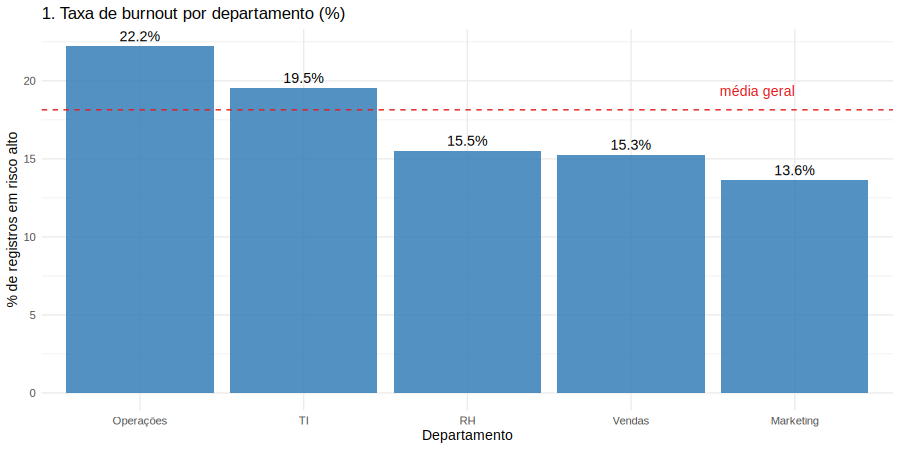

In [8]:
%%R -w 900 -h 450 -u px
cores <- c("0" = "#4daf4a", "1" = "#e41a1c")
rotulos <- c("0" = "Baixo", "1" = "Alto")
df_tratado$risco <- factor(df_tratado$risco_burnout, levels = c(0, 1), labels = c("Baixo", "Alto"))
cores_f <- c("Baixo" = "#4daf4a", "Alto" = "#e41a1c")

# ---- Gráfico 1: taxa de burnout por departamento ----
g1 <- df_tratado %>% group_by(departamento) %>%
  summarise(taxa = 100 * mean(risco_burnout), .groups = "drop")
taxa_geral <- 100 * mean(df_tratado$risco_burnout)
p1 <- ggplot(g1, aes(x = reorder(departamento, -taxa), y = taxa)) +
  geom_col(fill = "#377eb8", alpha = 0.85) +
  geom_text(aes(label = paste0(round(taxa, 1), "%")), vjust = -0.5, size = 5) +
  geom_hline(yintercept = taxa_geral, linetype = "dashed", color = "#e41a1c") +
  annotate("text", x = 5, y = taxa_geral + 1.2, label = "média geral", color = "#e41a1c", hjust = 1) +
  theme_minimal(base_size = 14) +
  labs(title = "1. Taxa de burnout por departamento (%)", x = "Departamento", y = "% de registros em risco alto")
print(p1)


**Gráfico 1 - Taxa de burnout por departamento.** Operações lidera (~22%), seguido por TI (~19–20%); RH e Vendas ficam em torno de 15% e Marketing é o menor (~14%). Usamos **taxa (%)**, e não contagem, porque os setores têm tamanhos diferentes (um setor grande teria mais casos só por ter mais gente). Dois setores ficam acima da média geral e merecem atenção prioritária.

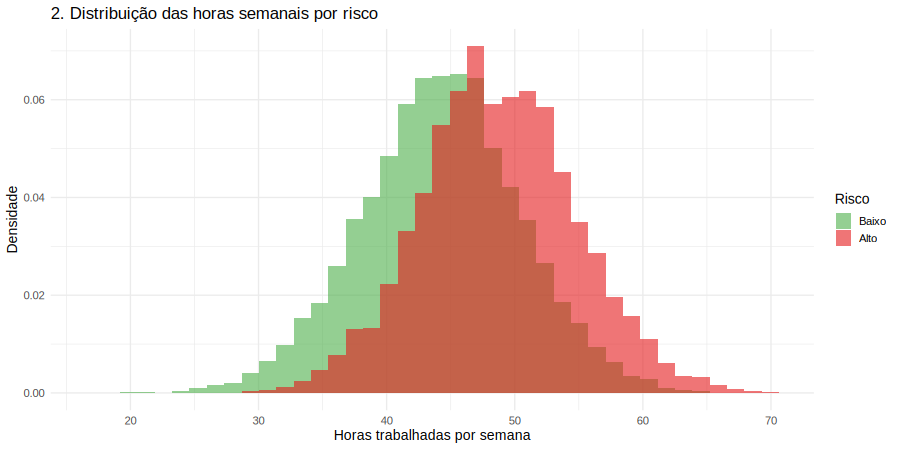

In [9]:
%%R -w 900 -h 450 -u px
# ---- Gráfico 2: distribuição das horas trabalhadas por grupo de risco ----
p2 <- ggplot(df_tratado, aes(x = horas_trabalhadas_semana, fill = risco)) +
  geom_histogram(aes(y = after_stat(density)), bins = 40, position = "identity", alpha = 0.6) +
  scale_fill_manual(values = cores_f, name = "Risco") +
  theme_minimal(base_size = 14) +
  labs(title = "2. Distribuição das horas semanais por risco", x = "Horas trabalhadas por semana", y = "Densidade")
print(p2)


**Gráfico 2 - Horas semanais por grupo de risco.** A distribuição do grupo de risco alto está deslocada para a direita (média ~48,7 h contra ~44,3 h). Há **grande sobreposição**: muita gente trabalha 50 h sem risco alto. Conclusão: a carga horária **eleva a probabilidade**, mas não é suficiente sozinha para separar os grupos, o que justifica combinar várias variáveis em um modelo.

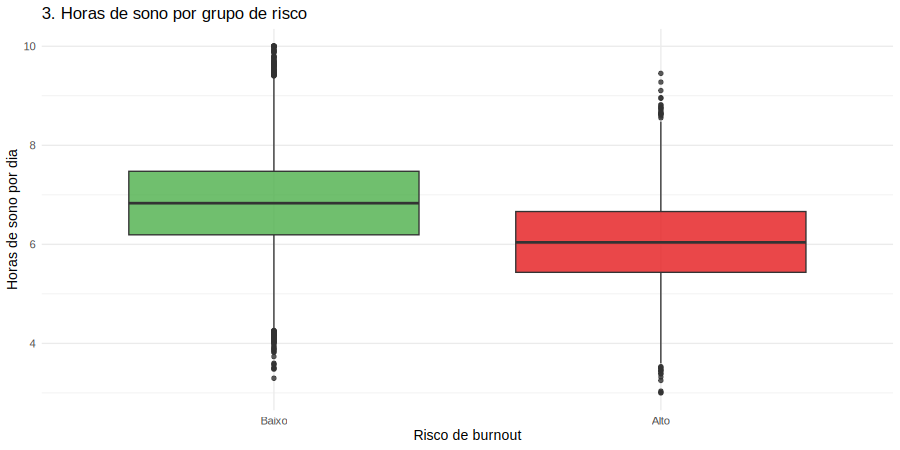

In [10]:
%%R -w 900 -h 450 -u px
# ---- Gráfico 3: boxplot de horas de sono por grupo de risco ----
p3 <- ggplot(df_tratado, aes(x = risco, y = horas_sono_diarias, fill = risco)) +
  geom_boxplot(alpha = 0.8) +
  scale_fill_manual(values = cores_f, guide = "none") +
  theme_minimal(base_size = 14) +
  labs(title = "3. Horas de sono por grupo de risco", x = "Risco de burnout", y = "Horas de sono por dia")
print(p3)


**Gráfico 3 - Horas de sono por grupo de risco.** A mediana de sono do grupo de risco alto é visivelmente menor (~6,0 h contra ~6,8 h) e a caixa inteira se desloca para baixo. O sono curto aparece como sinal consistente, com sobreposição parcial entre os grupos.

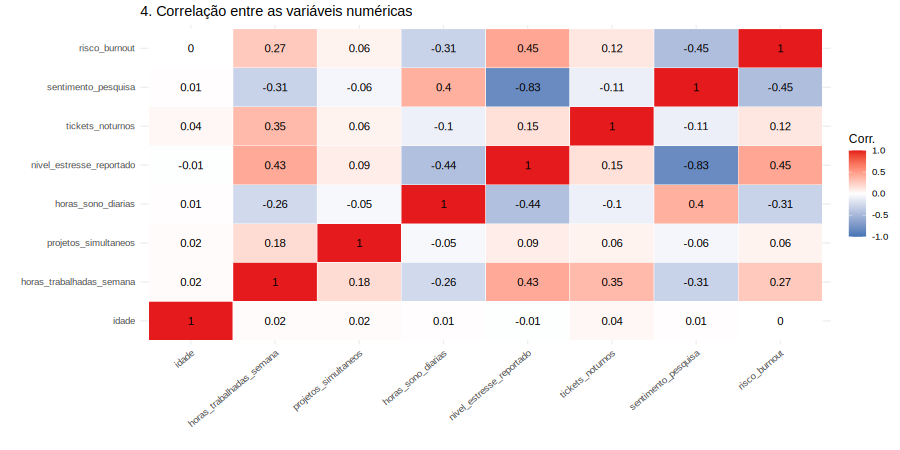

In [11]:
%%R -w 900 -h 450 -u px
# ---- Gráfico 4: mapa de calor de correlações ----
vars_cor <- c("idade", "horas_trabalhadas_semana", "projetos_simultaneos", "horas_sono_diarias",
              "nivel_estresse_reportado", "tickets_noturnos", "sentimento_pesquisa", "risco_burnout")
cm <- round(cor(df_tratado[vars_cor]), 2)
cm_long <- as.data.frame(as.table(cm)); names(cm_long) <- c("Var1", "Var2", "valor")
p4 <- ggplot(cm_long, aes(x = Var1, y = Var2, fill = valor)) +
  geom_tile(color = "white") +
  geom_text(aes(label = valor), size = 4) +
  scale_fill_gradient2(low = "#4575b4", mid = "white", high = "#e41a1c", midpoint = 0, limits = c(-1, 1), name = "Corr.") +
  theme_minimal(base_size = 12) +
  theme(axis.text.x = element_text(angle = 40, hjust = 1)) +
  labs(title = "4. Correlação entre as variáveis numéricas", x = "", y = "")
print(p4)


**Gráfico 4 - Correlação.** As maiores correlações com o risco são **estresse (+0,45)** e **sentimento da pesquisa (−0,45)**, seguidas de **sono (−0,31)** e **horas (+0,27)**; tickets noturnos têm +0,12; `idade` e `projetos_simultaneos` são praticamente nulas. Dois alertas: (i) **estresse e sentimento têm correlação de −0,83**, ou seja, carregam informação quase redundante, o que dilui a importância individual de cada um no modelo; (ii) horas se correlaciona com estresse (+0,43) e tickets noturnos (+0,35): a carga horária alimenta as outras pressões.

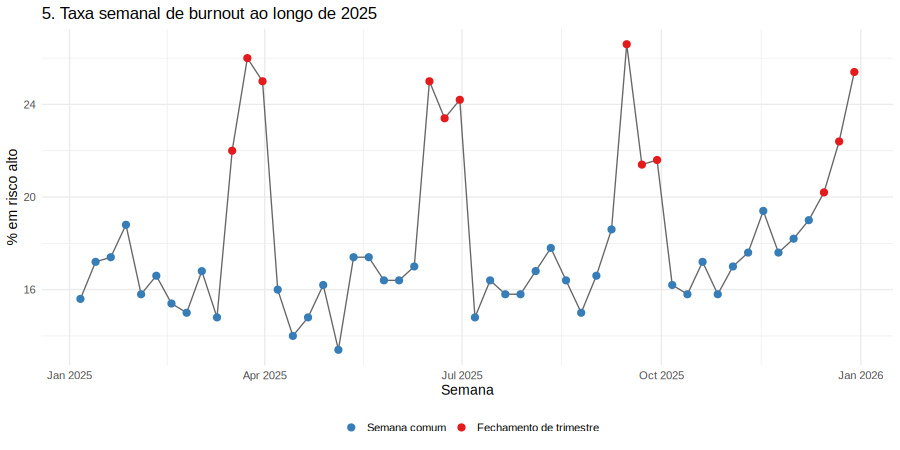

In [12]:
%%R -w 900 -h 450 -u px
# ---- Gráfico 5: série temporal da taxa semanal de burnout ----
sem <- df_tratado %>% mutate(data_semana = as.Date(data_semana)) %>%
  group_by(data_semana) %>% summarise(taxa = 100 * mean(risco_burnout), .groups = "drop") %>%
  arrange(data_semana)
sem$pico_trimestre <- ((seq_len(nrow(sem)) - 1) %% 13 + 1) %in% 11:13   # 3 últimas semanas de cada trimestre
p5 <- ggplot(sem, aes(x = data_semana, y = taxa)) +
  geom_line(color = "grey40") +
  geom_point(aes(color = pico_trimestre), size = 3) +
  scale_color_manual(values = c("FALSE" = "#377eb8", "TRUE" = "#e41a1c"),
                     labels = c("Semana comum", "Fechamento de trimestre"), name = "") +
  theme_minimal(base_size = 14) + theme(legend.position = "bottom") +
  labs(title = "5. Taxa semanal de burnout ao longo de 2025", x = "Semana", y = "% em risco alto")
print(p5)


**Gráfico 5 - Série temporal.** O risco tem **sazonalidade clara**: nas 3 últimas semanas de cada trimestre (pontos vermelhos) a taxa sobe para ~22–26%, contra ~13–19% nas semanas comuns, e volta a cair logo depois. Isso indica que o risco responde a **picos de pressão de fechamento**, e que alertas baseados em calendário podem ser tão úteis quanto os baseados em indivíduos.

`geom_smooth()` using formula = 'y ~ x'


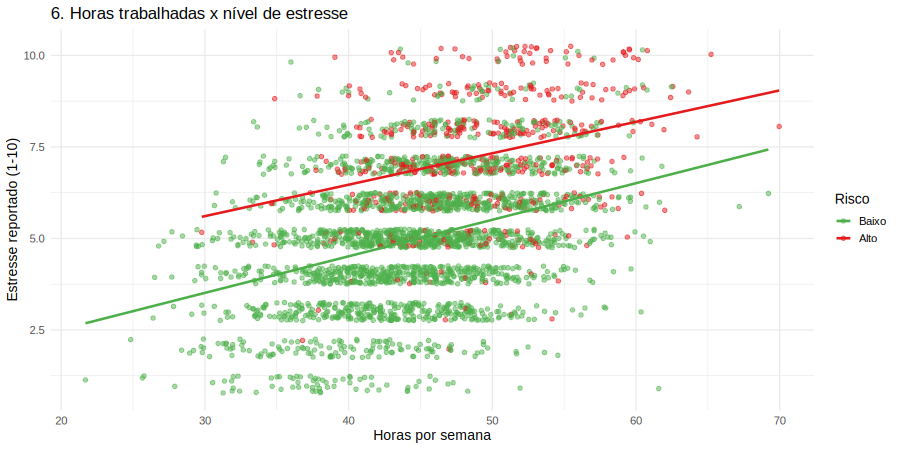

In [13]:
%%R -w 900 -h 450 -u px
# ---- Gráfico 6: horas x estresse (amostra de 3.000 registros) ----
set.seed(1)
amostra <- df_tratado[sample(nrow(df_tratado), 3000), ]
p6 <- ggplot(amostra, aes(x = horas_trabalhadas_semana, y = nivel_estresse_reportado, color = risco)) +
  geom_jitter(width = 0, height = 0.25, alpha = 0.5, size = 1.8) +
  geom_smooth(method = "lm", se = FALSE, linewidth = 1.2) +
  scale_color_manual(values = cores_f, name = "Risco") +
  theme_minimal(base_size = 14) +
  labs(title = "6. Horas trabalhadas x nível de estresse", x = "Horas por semana", y = "Estresse reportado (1-10)")
print(p6)


**Gráfico 6 - Horas × estresse.** O estresse reportado **cresce com as horas trabalhadas** (retas ascendentes nos dois grupos). Os pontos de risco alto se concentram na faixa superior de estresse em qualquer nível de horas: a separação é principalmente **vertical (estresse)**, e a carga horária desloca ambos os grupos para a direita. É a relação esperada: horas explicam parte do estresse, mas não todo.

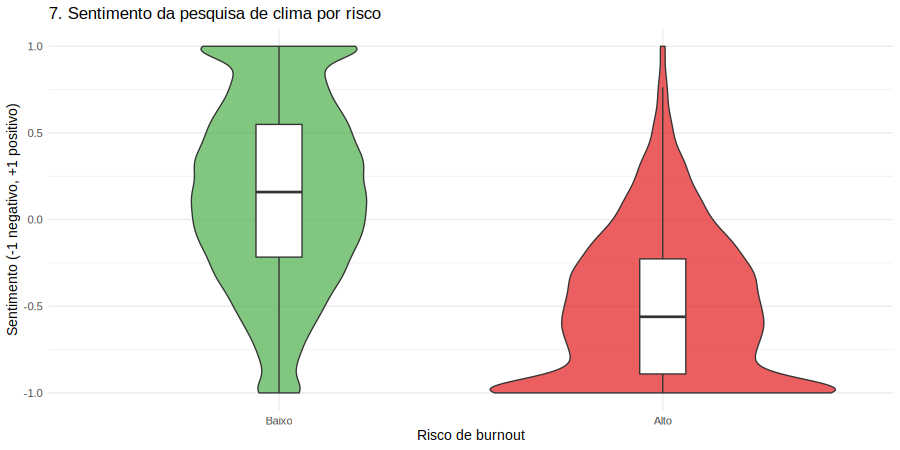

In [14]:
%%R -w 900 -h 450 -u px
# ---- Gráfico 7: sentimento dos comentários (saída simulada de NLP) por grupo de risco ----
p7 <- ggplot(df_tratado, aes(x = risco, y = sentimento_pesquisa, fill = risco)) +
  geom_violin(alpha = 0.7) +
  geom_boxplot(width = 0.12, fill = "white", outlier.shape = NA) +
  scale_fill_manual(values = cores_f, guide = "none") +
  theme_minimal(base_size = 14) +
  labs(title = "7. Sentimento da pesquisa de clima por risco", x = "Risco de burnout", y = "Sentimento (-1 negativo, +1 positivo)")
print(p7)


**Gráfico 7 - Sentimento da pesquisa por risco.** O grupo de risco alto concentra-se em sentimento **negativo** (mediana em torno de −0,5) e o de risco baixo em sentimento positivo, com sobreposição pequena na região negativa. Se, no mundo real, o NLP sobre comentários capturar isso, seria um dos melhores sinais precoces. **Ressalva:** aqui o sentimento é simulado, e foi construído para refletir o estresse (por isso a forte associação).

## 5. Arquitetura: Data Lake + Data Warehouse

### 5.1 Decisão e justificativa
A orientação da disciplina indica **Data Warehouse** para dados predominantemente estruturados e **Data Lake** para dados não/semiestruturados, admitindo também a **integração entre ambos**. Nossa base é tabular (estruturada), o que aponta para o DW. Porém o projeto prevê fontes que **não são tabulares** (comentários livres e logs JSON de tickets). Por isso adotamos uma **arquitetura híbrida**:

| Camada | Tipo | Formato | Conteúdo | Ferramenta |
|---|---|---|---|---|
| **RAW** (Lake) | Dado original, intocado | CSV | `burnout_bruto.csv` + dicionário | Python (ingestão) |
| **SILVER** (Lake) | Dado limpo e padronizado | CSV (saída do R) → **Parquet particionado** por ano/trimestre | Base tratada + colunas derivadas | R (tratamento) + Spark |
| **GOLD = Data Warehouse** | Dado modelado para análise | **Parquet**, esquema estrela | 1 fato + 3 dimensões | Spark |

- O **Lake** preserva o dado cru (permite reprocessar se a regra de limpeza mudar) e é a porta de entrada para dados futuros não estruturados.
- O **DW em esquema estrela** dá consultas OLAP simples e rápidas, com uma hierarquia de tempo (ano > trimestre > mês > semana).
- **Parquet** é colunar e comprimido: lê só as colunas pedidas, e o particionamento por ano/trimestre permite ler só os períodos necessários, o que é essencial em volumes grandes.

### 5.2 Diagramas
A célula abaixo desenha (e salva em PNG) o **diagrama da arquitetura** ponta a ponta e o **modelo dimensional**.

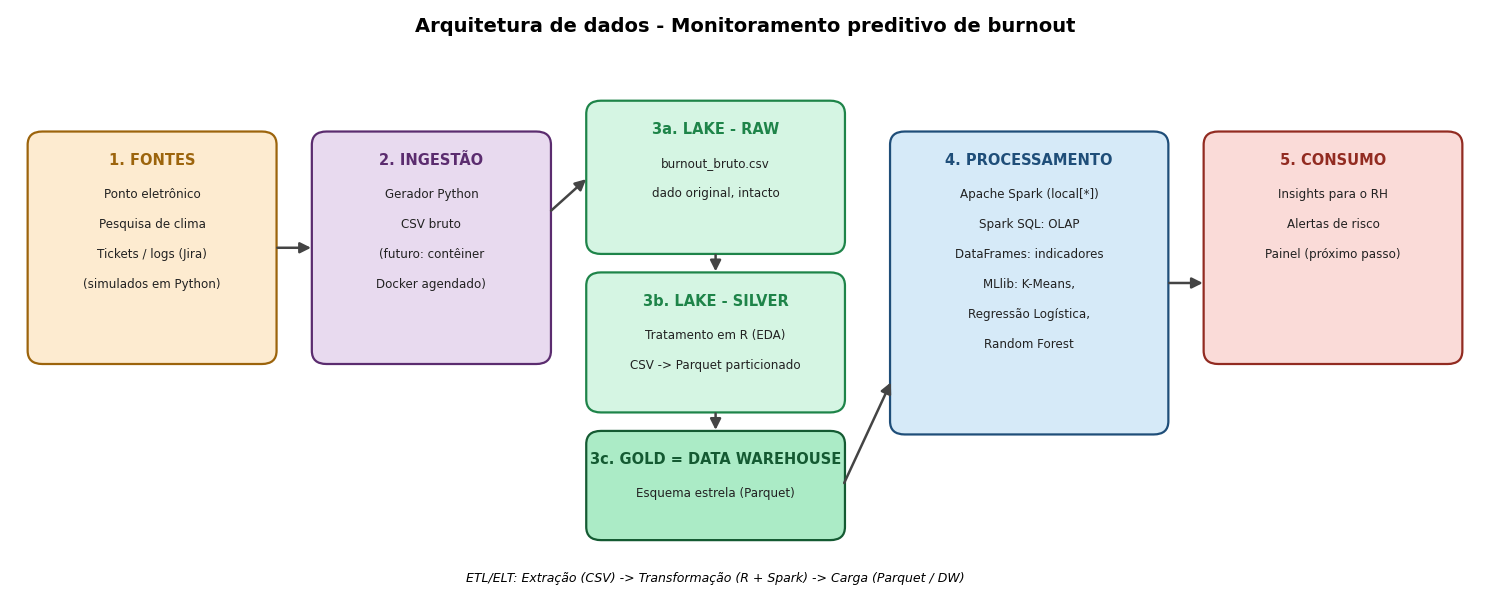

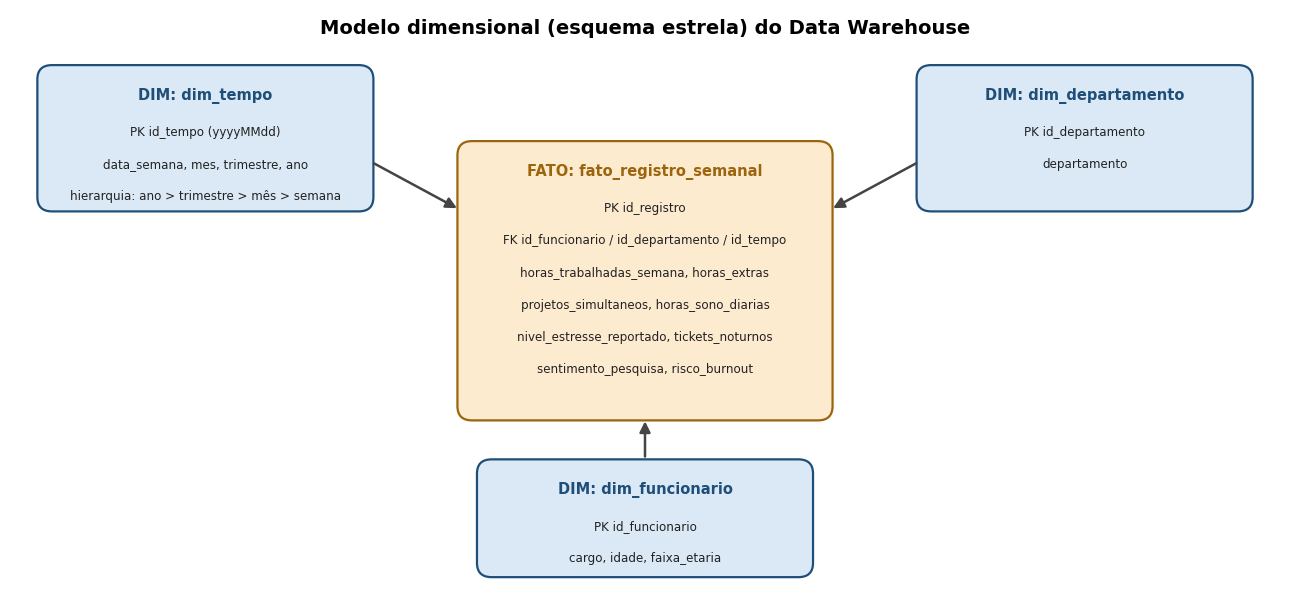

In [15]:
# ==== Diagramas: arquitetura ponta a ponta e modelo dimensional (esquema estrela) ====
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def caixa(ax, x, y, w, h, titulo, linhas=(), cor="#dbe9f6", borda="#1f4e79"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.15",
                                fc=cor, ec=borda, lw=1.6))
    ax.text(x + w / 2, y + h - 0.22, titulo, ha="center", va="top", fontsize=10.5, fontweight="bold", color=borda)
    for i, t in enumerate(linhas):
        ax.text(x + w / 2, y + h - 0.62 - i * 0.34, t, ha="center", va="top", fontsize=8.6, color="#222")

def seta(ax, x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=16, lw=1.8, color="#444"))

# ---------- Diagrama 1: arquitetura ----------
fig, ax = plt.subplots(figsize=(15, 6.2))
ax.set_xlim(0, 15); ax.set_ylim(-0.5, 6.2); ax.axis("off")
ax.text(7.5, 5.95, "Arquitetura de dados - Monitoramento preditivo de burnout", ha="center", fontsize=14, fontweight="bold")

caixa(ax, 0.2, 2.2, 2.5, 2.6, "1. FONTES", ["Ponto eletrônico", "Pesquisa de clima", "Tickets / logs (Jira)", "(simulados em Python)"], "#fdebd0", "#9c640c")
caixa(ax, 3.1, 2.2, 2.4, 2.6, "2. INGESTÃO", ["Gerador Python", "CSV bruto", "(futuro: contêiner", "Docker agendado)"], "#e8daef", "#5b2c6f")
caixa(ax, 5.9, 3.45, 2.6, 1.7, "3a. LAKE - RAW", ["burnout_bruto.csv", "dado original, intacto"], "#d5f5e3", "#1e8449")
caixa(ax, 5.9, 1.65, 2.6, 1.55, "3b. LAKE - SILVER", ["Tratamento em R (EDA)", "CSV -> Parquet particionado"], "#d5f5e3", "#1e8449")
caixa(ax, 5.9, 0.2, 2.6, 1.2, "3c. GOLD = DATA WAREHOUSE", ["Esquema estrela (Parquet)"], "#abebc6", "#145a32")
caixa(ax, 9.0, 1.4, 2.8, 3.4, "4. PROCESSAMENTO", ["Apache Spark (local[*])", "Spark SQL: OLAP", "DataFrames: indicadores", "MLlib: K-Means,", "Regressão Logística,", "Random Forest"], "#d6eaf8", "#1f4e79")
caixa(ax, 12.2, 2.2, 2.6, 2.6, "5. CONSUMO", ["Insights para o RH", "Alertas de risco", "Painel (próximo passo)"], "#fadbd8", "#922b21")

seta(ax, 2.7, 3.5, 3.1, 3.5); seta(ax, 5.5, 3.9, 5.9, 4.3)
seta(ax, 7.2, 3.45, 7.2, 3.2); seta(ax, 7.2, 1.65, 7.2, 1.4)
seta(ax, 8.5, 0.8, 9.0, 2.0); seta(ax, 11.8, 3.1, 12.2, 3.1)
ax.text(7.2, -0.3, "ETL/ELT: Extração (CSV) -> Transformação (R + Spark) -> Carga (Parquet / DW)", ha="center", fontsize=9, style="italic")
plt.tight_layout(); plt.savefig("arquitetura.png", dpi=150, bbox_inches="tight"); plt.show()

# ---------- Diagrama 2: esquema estrela ----------
fig, ax = plt.subplots(figsize=(13, 6))
ax.set_xlim(0, 13); ax.set_ylim(0, 6); ax.axis("off")
ax.text(6.5, 5.75, "Modelo dimensional (esquema estrela) do Data Warehouse", ha="center", fontsize=14, fontweight="bold")
caixa(ax, 4.6, 1.7, 3.8, 2.9, "FATO: fato_registro_semanal",
      ["PK id_registro", "FK id_funcionario / id_departamento / id_tempo", "horas_trabalhadas_semana, horas_extras",
       "projetos_simultaneos, horas_sono_diarias", "nivel_estresse_reportado, tickets_noturnos",
       "sentimento_pesquisa, risco_burnout"], "#fdebd0", "#9c640c")
caixa(ax, 0.3, 3.9, 3.4, 1.5, "DIM: dim_tempo", ["PK id_tempo (yyyyMMdd)", "data_semana, mes, trimestre, ano", "hierarquia: ano > trimestre > mês > semana"])
caixa(ax, 9.3, 3.9, 3.4, 1.5, "DIM: dim_departamento", ["PK id_departamento", "departamento"])
caixa(ax, 4.8, 0.05, 3.4, 1.2, "DIM: dim_funcionario", ["PK id_funcionario", "cargo, idade, faixa_etaria"])
seta(ax, 3.7, 4.4, 4.6, 3.9); seta(ax, 9.3, 4.4, 8.4, 3.9); seta(ax, 6.5, 1.27, 6.5, 1.7)
plt.tight_layout(); plt.savefig("esquema_estrela.png", dpi=150, bbox_inches="tight"); plt.show()


## 6. ETL/ELT com Apache Spark

O fluxo completo do projeto, com a divisão de responsabilidades entre as linguagens:

| Etapa | O que acontece | Onde |
|---|---|---|
| **E - Extract** | Geração/ingestão do CSV bruto → leitura da zona silver | Python (seção 3) e Spark |
| **T - Transform** | Limpeza e padronização; depois colunas derivadas (`ano`, `trimestre`, `mes`, `horas_extras`, `faixa_etaria`, `id_tempo`) e construção das dimensões e do fato | R (seção 4) e Spark |
| **L - Load** | Gravação em Parquet: silver particionada e gold (DW) | Spark |

Como a base já está no Lake antes de ser transformada, o desenho é **ELT** para a camada gold: o dado cru é carregado primeiro e transformado depois, dentro da própria plataforma.

In [16]:
# ==== ETL/ELT com Apache Spark: Silver (CSV do R) -> Parquet particionado -> Gold (Data Warehouse) ====
import os
from pyspark.sql import SparkSession, functions as F, Window

spark = (SparkSession.builder.appName("Pipeline_Burnout").master("local[*]")
         .config("spark.sql.shuffle.partitions", "8").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

# ---------- E (Extract): lê a zona SILVER gerada pelo R ----------
silver = (spark.read.csv("datalake/silver/burnout_tratado.csv", header=True, inferSchema=True)
          .withColumn("data_semana", F.to_date("data_semana")))
print(f"[E] Registros extraídos da zona SILVER: {silver.count():,}")

# ---------- T (Transform): colunas derivadas ----------
silver = (silver
    .withColumn("ano", F.year("data_semana"))
    .withColumn("trimestre", F.quarter("data_semana"))
    .withColumn("mes", F.month("data_semana"))
    .withColumn("horas_extras", F.greatest(F.col("horas_trabalhadas_semana") - 40, F.lit(0.0)))
    .withColumn("faixa_etaria", F.when(F.col("idade") < 30, "22-29").when(F.col("idade") < 40, "30-39")
                                 .when(F.col("idade") < 50, "40-49").otherwise("50+"))
    .withColumn("id_tempo", F.date_format("data_semana", "yyyyMMdd").cast("int")))

# Silver em Parquet (colunar, comprimido) e PARTICIONADO por ano/trimestre -> leitura seletiva em volumes grandes
silver.write.mode("overwrite").partitionBy("ano", "trimestre").parquet("datalake/silver/burnout_parquet")

# ---------- T: modelo dimensional ----------
dim_departamento = (silver.select("departamento").distinct()
    .withColumn("id_departamento", F.dense_rank().over(Window.orderBy("departamento")))
    .select("id_departamento", "departamento"))
dim_funcionario = silver.select("id_funcionario", "cargo", "idade", "faixa_etaria").distinct()
dim_tempo = silver.select("id_tempo", "data_semana", "ano", "trimestre", "mes").distinct()
fato = (silver.join(dim_departamento, "departamento")
    .select("id_registro", "id_funcionario", "id_departamento", "id_tempo",
            "horas_trabalhadas_semana", "horas_extras", "projetos_simultaneos", "horas_sono_diarias",
            "nivel_estresse_reportado", "tickets_noturnos", "sentimento_pesquisa", "risco_burnout"))

# ---------- L (Load): zona GOLD = Data Warehouse ----------
gold = "datalake/gold"
for nome, d in [("dim_departamento", dim_departamento), ("dim_funcionario", dim_funcionario),
                ("dim_tempo", dim_tempo), ("fato_registro_semanal", fato)]:
    d.write.mode("overwrite").parquet(f"{gold}/{nome}")

# Recarrega do Parquet (o que as análises consomem) e registra as views para o Spark SQL
for nome in ["dim_departamento", "dim_funcionario", "dim_tempo", "fato_registro_semanal"]:
    spark.read.parquet(f"{gold}/{nome}").createOrReplaceTempView(nome)

print("\n[L] Tabelas do Data Warehouse carregadas:")
for nome in ["dim_departamento", "dim_funcionario", "dim_tempo", "fato_registro_semanal"]:
    print(f"    {nome:<24} {spark.table(nome).count():>7,} linhas")

print("\nEvidência de execução - estrutura física do Data Lake:")
for raiz in ["datalake/raw", "datalake/silver/burnout_parquet", "datalake/gold"]:
    for pasta, subs, arqs in sorted(os.walk(raiz)):
        if pasta.count("/") <= (4 if "burnout_parquet" in pasta else 2):
            print("   ", pasta, f"({len(arqs)} arquivo(s))" if arqs else "")


[E] Registros extraídos da zona SILVER: 26,000

[L] Tabelas do Data Warehouse carregadas:
    dim_departamento               5 linhas
    dim_funcionario              500 linhas
    dim_tempo                     52 linhas
    fato_registro_semanal     26,000 linhas

Evidência de execução - estrutura física do Data Lake:
    datalake/raw (2 arquivo(s))
    datalake/silver/burnout_parquet (2 arquivo(s))
    datalake/silver/burnout_parquet/ano=2025 
    datalake/silver/burnout_parquet/ano=2025/trimestre=1 (2 arquivo(s))
    datalake/silver/burnout_parquet/ano=2025/trimestre=2 (2 arquivo(s))
    datalake/silver/burnout_parquet/ano=2025/trimestre=3 (2 arquivo(s))
    datalake/silver/burnout_parquet/ano=2025/trimestre=4 (2 arquivo(s))
    datalake/gold 
    datalake/gold/dim_departamento (4 arquivo(s))
    datalake/gold/dim_funcionario (4 arquivo(s))
    datalake/gold/dim_tempo (4 arquivo(s))
    datalake/gold/fato_registro_semanal (4 arquivo(s))


## 7. OLAP sobre o Data Warehouse

Cinco operações OLAP sobre o esquema estrela, cada uma ligada a uma pergunta do problema:

| Operação | Pergunta de negócio |
|---|---|
| **Roll-up** | O risco muda do mês para o trimestre e para o total? Onde estão os picos? |
| **Drill-down** | Dentro do pior trimestre, qual é o pior mês e a pior semana? |
| **Slice** | Como se comporta **apenas** o setor de TI ao longo do ano? |
| **Dice** | E o subgrupo Júnior/Pleno de TI e Operações, em T1 e T4? |
| **Pivot** | Como o risco por setor varia por trimestre? |

In [17]:
# ==== OLAP via Spark SQL sobre o esquema estrela ====

from pyspark.sql import functions as F

JOIN_BASE = """
    FROM fato_registro_semanal f
    JOIN dim_tempo t
        ON f.id_tempo = t.id_tempo
    JOIN dim_departamento d
        ON f.id_departamento = d.id_departamento
    JOIN dim_funcionario fu
        ON f.id_funcionario = fu.id_funcionario
"""

# =========================================================
# 1) ROLL-UP: mês -> trimestre -> total
# =========================================================

print("=== 1) ROLL-UP: mês -> trimestre -> total (taxa de burnout) ===")

spark.sql(f"""
    WITH agregado AS (
        SELECT
            t.trimestre AS trimestre_original,
            t.mes AS mes_original,

            GROUPING(t.trimestre) AS nivel_total,
            GROUPING(t.mes) AS nivel_trimestre,

            COUNT(*) AS registros,
            ROUND(100 * AVG(f.risco_burnout), 1) AS taxa_burnout_pct,
            ROUND(AVG(f.horas_trabalhadas_semana), 1) AS media_horas

        {JOIN_BASE}

        GROUP BY ROLLUP(t.trimestre, t.mes)
    )

    SELECT
        COALESCE(CAST(trimestre_original AS STRING), 'TOTAL') AS trimestre,
        COALESCE(CAST(mes_original AS STRING), '-') AS mes,
        registros,
        taxa_burnout_pct,
        media_horas

    FROM agregado

    ORDER BY
        nivel_total,
        trimestre_original,
        nivel_trimestre,
        mes_original

""").show(30, truncate=False)


# =========================================================
# 2) DRILL-DOWN: trimestre -> mês -> semana
# =========================================================

print("=== 2) DRILL-DOWN: do trimestre mais crítico até a semana mais crítica ===")

pior_tri = spark.sql(f"""
    SELECT
        t.trimestre,
        AVG(f.risco_burnout) AS media_risco

    {JOIN_BASE}

    GROUP BY t.trimestre
    ORDER BY media_risco DESC
    LIMIT 1

""").first()["trimestre"]

print(f"Nível 1 - trimestre mais crítico: T{pior_tri}. Descendo para os meses:")

meses = spark.sql(f"""
    SELECT
        t.mes,
        COUNT(*) AS registros,
        ROUND(100 * AVG(f.risco_burnout), 1) AS taxa_burnout_pct

    {JOIN_BASE}

    WHERE t.trimestre = {int(pior_tri)}

    GROUP BY t.mes
    ORDER BY t.mes

""")

meses.show(truncate=False)

pior_mes = meses.orderBy(
    F.desc("taxa_burnout_pct")
).first()["mes"]

print(f"Nível 2 - mês mais crítico: {pior_mes}. Descendo para as semanas:")

spark.sql(f"""
    SELECT
        t.data_semana,
        ROUND(100 * AVG(f.risco_burnout), 1) AS taxa_burnout_pct,
        ROUND(AVG(f.horas_trabalhadas_semana), 1) AS media_horas

    {JOIN_BASE}

    WHERE t.mes = {int(pior_mes)}

    GROUP BY t.data_semana
    ORDER BY t.data_semana

""").show(30, truncate=False)


# =========================================================
# 3) SLICE: fixa uma dimensão (departamento = TI)
# =========================================================

print("=== 3) SLICE: fixa UMA dimensão (departamento = 'TI') ===")

spark.sql(f"""
    SELECT
        t.trimestre,
        COUNT(*) AS registros,
        ROUND(100 * AVG(f.risco_burnout), 1) AS taxa_burnout_pct,
        ROUND(AVG(f.tickets_noturnos), 2) AS tickets_noturnos_medios

    {JOIN_BASE}

    WHERE d.departamento = 'TI'

    GROUP BY t.trimestre
    ORDER BY t.trimestre

""").show(truncate=False)


# =========================================================
# 4) DICE: subcubo com várias dimensões
# =========================================================

print("=== 4) DICE: TI e Operações x Júnior e Pleno x T1 e T4 ===")

spark.sql(f"""
    SELECT
        d.departamento,
        fu.cargo,
        t.trimestre,
        COUNT(*) AS registros,
        ROUND(100 * AVG(f.risco_burnout), 1) AS taxa_burnout_pct

    {JOIN_BASE}

    WHERE
        d.departamento IN ('TI', 'Operações')
        AND fu.cargo IN ('Júnior', 'Pleno')
        AND t.trimestre IN (1, 4)

    GROUP BY
        d.departamento,
        fu.cargo,
        t.trimestre

    ORDER BY
        d.departamento,
        fu.cargo,
        t.trimestre

""").show(truncate=False)


# =========================================================
# 5) PIVOT: departamento x trimestre
# =========================================================

print("=== 5) PIVOT: departamento x trimestre (taxa de burnout %) ===")

(
    spark.table("fato_registro_semanal")
    .join(
        spark.table("dim_tempo"),
        "id_tempo"
    )
    .join(
        spark.table("dim_departamento"),
        "id_departamento"
    )
    .groupBy("departamento")
    .pivot("trimestre", [1, 2, 3, 4])
    .agg(
        F.round(100 * F.avg("risco_burnout"), 1)
    )
    .orderBy("departamento")
    .show(truncate=False)
)

print("=== ANÁLISE OLAP FINALIZADA ===")

=== 1) ROLL-UP: mês -> trimestre -> total (taxa de burnout) ===
+---------+---+---------+----------------+-----------+
|trimestre|mes|registros|taxa_burnout_pct|media_horas|
+---------+---+---------+----------------+-----------+
|1        |1  |2000     |17.3            |44.2       |
|1        |2  |2000     |15.7            |44.2       |
|1        |3  |2500     |20.9            |46.6       |
|1        |-  |6500     |18.2            |45.1       |
|2        |4  |2000     |15.3            |44.0       |
|2        |5  |2000     |16.2            |44.1       |
|2        |6  |2500     |21.2            |46.5       |
|2        |-  |6500     |17.8            |45.0       |
|3        |7  |2000     |15.7            |44.1       |
|3        |8  |2000     |16.5            |44.3       |
|3        |9  |2500     |21.0            |46.5       |
|3        |-  |6500     |18.0            |45.1       |
|4        |10 |2000     |16.3            |44.2       |
|4        |11 |2000     |17.9            |44.0       |
|

**Interpretação do OLAP:**
- **Roll-up:** os trimestres têm risco quase idêntico (~18%), mas **dentro de cada trimestre o mês de fechamento (mar, jun, set, dez) tem ~21%, contra ~16–17% nos outros meses**, com média de horas ~2 h maior. O padrão relevante é o **mês de fechamento**, não o trimestre.
- **Drill-down:** o trimestre "mais crítico" (T4) vence por margem pequena, mas ao descer até as semanas vemos que a **última semana do ano é a pior** (~25%), com horas médias de ~48 h. A decisão prática é agir nas semanas de fechamento, e não em um trimestre inteiro.
- **Slice (TI):** o risco de TI é **estável ao longo do ano** (~18–20%) e o fechamento de tickets fora do expediente é cerca de **o dobro ou mais** do que se vê nos demais setores. A pressão de TI é estrutural, não sazonal.
- **Dice:** Operações (Júnior e Pleno) fica em ~21–24%, acima de TI (~17–19%) no mesmo recorte, e sobe de T1 para T4.
- **Pivot:** Operações é o setor de maior risco em **todos** os trimestres e piora no T4 (~24%); Marketing é o menor na maior parte dos trimestres.

## 8. Spark DataFrames, indicadores e escalabilidade

### 8.1 Por que Spark (e por que não Hadoop MapReduce puro)
| Pergunta da disciplina | Nossa resposta |
|---|---|
| **O volume atual justifica Spark?** | Não por si só: 26 mil linhas rodariam em pandas. Usamos Spark para **validar e demonstrar a arquitetura que escala**; o mesmo código (DataFrames, Spark SQL, MLlib) roda em cluster **sem reescrita** |
| **E a variedade e a velocidade?** | A arquitetura prevê logs JSON, texto livre e dados contínuos. Spark lê CSV, JSON e Parquet com a mesma API e tem Structured Streaming para dados em fluxo |
| **Por que não só Hadoop/MapReduce?** | MapReduce grava resultados intermediários em disco a cada etapa, o que é lento para consultas iterativas e para ML. Spark processa em memória e unifica SQL, DataFrames e MLlib |

### 8.2 Papel dos componentes do ecossistema na versão em produção
| Componente | Papel no projeto | Neste notebook |
|---|---|---|
| **HDFS** | Armazenamento distribuído e replicado do Lake (raw/silver/gold) no lugar da pasta local | Simulado pela pasta `datalake/` |
| **YARN** | Gerenciador de recursos que distribui os jobs Spark pelos nós do cluster | Substituído por `master("local[*]")` (usa os núcleos locais) |
| **Hive** | Catálogo/metastore das tabelas do DW sobre os Parquet, consultável por SQL | Substituído por *temp views* do Spark SQL |
| **Spark DataFrames / Spark SQL** | Transformações, OLAP e indicadores | **Executados** nas seções 6, 7 e 8 |
| **Spark MLlib** | K-Means e classificação distribuídos | **Executados** nas seções 9 e 10 |

### 8.3 Como escalaria para volumes maiores
1. **Armazenamento:** trocar `datalake/...` por `hdfs://...` ou um *object storage* (S3/GCS). O código de leitura/escrita em Parquet é o mesmo.
2. **Execução:** trocar `master("local[*]")` por um cluster gerenciado (YARN, Databricks, EMR, Dataproc). DataFrames e SQL não mudam.
3. **Dados:** o particionamento por ano/trimestre permite que uma consulta de um trimestre leia só aquela pasta (poda de partições). Parquet colunar lê só as colunas necessárias.
4. **Ingestão contínua:** Kafka/Structured Streaming para ponto e tickets em fluxo, com microlotes alimentando a camada bronze/raw.
5. **Orquestração:** o pipeline pode ser agendado em contêineres Docker, conforme previsto na proposta do projeto.

### 8.4 Indicadores com a API de DataFrames
Seleção, filtro, agrupamento, ordenação e cálculo de indicadores (incluindo um **Índice de Exaustão** de 0 a 100, que combina horas extras, estresse, déficit de sono e tickets noturnos).

In [18]:
# ==== Spark DataFrames: seleção, filtro, agrupamento, ordenação e indicadores ====
fato_df = spark.table("fato_registro_semanal")
wide = (fato_df.join(spark.table("dim_departamento"), "id_departamento")
               .join(spark.table("dim_tempo"), "id_tempo")
               .join(spark.table("dim_funcionario"), "id_funcionario"))

# Índice de Exaustão (0-100): combina 4 sinais, cada um normalizado em [0,1] e com peso igual
wide = wide.withColumn("indice_exaustao", 100 * (
      F.least(F.col("horas_extras") / 20, F.lit(1.0))
    + F.col("nivel_estresse_reportado") / 10
    + F.greatest(F.least((8 - F.col("horas_sono_diarias")) / 5, F.lit(1.0)), F.lit(0.0))
    + F.least(F.col("tickets_noturnos") / 5, F.lit(1.0))) / 4)

print("=== Indicadores por departamento (groupBy + agg + orderBy) ===")
(wide.groupBy("departamento").agg(
        F.count("*").alias("registros"),
        F.round(F.avg("horas_extras"), 1).alias("horas_extras_medias"),
        F.round(F.avg("nivel_estresse_reportado"), 2).alias("estresse_medio"),
        F.round(F.avg("horas_sono_diarias"), 2).alias("sono_medio"),
        F.round(F.avg("tickets_noturnos"), 2).alias("tickets_noturnos_medios"),
        F.round(F.avg("indice_exaustao"), 1).alias("indice_exaustao"),
        F.round(100 * F.avg("risco_burnout"), 1).alias("taxa_burnout_pct"))
     .orderBy(F.desc("indice_exaustao")).show(truncate=False))

print("=== Semanas críticas (filter): > 55 h trabalhadas E sono < 6 h ===")
(wide.filter((F.col("horas_trabalhadas_semana") > 55) & (F.col("horas_sono_diarias") < 6))
     .groupBy("departamento").agg(F.count("*").alias("semanas_criticas"),
                                  F.round(100 * F.avg("risco_burnout"), 1).alias("taxa_burnout_pct"))
     .orderBy(F.desc("semanas_criticas")).show())

print("=== Top 5 funcionários com maior índice médio de exaustão (select + groupBy + orderBy) ===")
(wide.select("id_funcionario", "departamento", "cargo", "indice_exaustao")
     .groupBy("id_funcionario", "departamento", "cargo")
     .agg(F.round(F.avg("indice_exaustao"), 1).alias("indice_medio"))
     .orderBy(F.desc("indice_medio")).limit(5).show())

print(f"Paralelismo: {spark.sparkContext.defaultParallelism} núcleos | partições do DataFrame: {wide.rdd.getNumPartitions()}")


=== Indicadores por departamento (groupBy + agg + orderBy) ===
+------------+---------+-------------------+--------------+----------+-----------------------+---------------+----------------+
|departamento|registros|horas_extras_medias|estresse_medio|sono_medio|tickets_noturnos_medios|indice_exaustao|taxa_burnout_pct|
+------------+---------+-------------------+--------------+----------+-----------------------+---------------+----------------+
|TI          |6864     |6.5                |5.45          |6.66      |1.56                   |36.4           |19.5            |
|Operações   |7540     |7.4                |5.7           |6.61      |0.81                   |34.6           |22.2            |
|Vendas      |4680     |5.4                |5.19          |6.74      |0.68                   |29.6           |15.3            |
|Marketing   |4576     |4.3                |5.03          |6.82      |0.61                   |27.2           |13.6            |
|RH          |2340     |3.1              

**Interpretação:**
- **TI tem o maior Índice de Exaustão (~36)**, puxado pelos tickets noturnos (~1,6 por semana, o dobro ou mais dos outros setores). **Operações tem a maior taxa de burnout (~22%)**, puxada pelas horas extras (~7,4 h). Os dois indicadores contam histórias diferentes: o índice mede **pressão acumulada**, a taxa mede **desfecho**. Priorizar só um deles esconderia o outro setor.
- **Regra simples de alerta (filtro):** semanas com **mais de 55 h e menos de 6 h de sono** têm risco alto em **44% a 67%** dos casos, contra ~18% na base toda. Essa regra interpretável pode funcionar como um primeiro alerta, antes de qualquer modelo.

## 9. Data Mining: perfis de risco com K-Means

**Objetivo:** descobrir, **sem usar o rótulo de burnout**, grupos naturais de semanas de trabalho, e só depois verificar quanto risco cada grupo concentra. É aprendizado **não supervisionado** (agrupamento): complementa a classificação da seção 10, que é supervisionada.

**Método:** K-Means com variáveis padronizadas (cada variável com média 0 e desvio 1, para que as horas, em dezenas, não dominem o sentimento, que varia de −1 a 1). Usamos horas, sono, estresse, tickets noturnos e sentimento. **O alvo não entra no agrupamento.**

**Escolha de k:** o coeficiente de silhueta é maior com k = 2, mas dois grupos apenas separam "tranquilo" de "pressionado", o que não acrescenta nada além do óbvio. Adotamos **k = 4**, que tem silhueta menor, porém separa perfis que levam a **ações diferentes**. É uma decisão de interpretabilidade, e não de otimização.

In [19]:
# ==== Data Mining: descoberta de perfis de risco com K-Means (aprendizado não supervisionado) ====
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

cols_cluster = ["horas_trabalhadas_semana", "horas_sono_diarias", "nivel_estresse_reportado",
                "tickets_noturnos", "sentimento_pesquisa"]       # o alvo (risco_burnout) NÃO entra: ele só valida os grupos depois
vec = VectorAssembler(inputCols=cols_cluster, outputCol="bruto").transform(wide)
scaler = StandardScaler(inputCol="bruto", outputCol="features", withMean=True, withStd=True).fit(vec)
base_km = scaler.transform(vec).select("*").cache()

print("Escolha do número de grupos (k) pelo coeficiente de silhueta:")
silhuetas = {}
for k in range(2, 7):
    modelo = KMeans(k=k, seed=42, featuresCol="features").fit(base_km)
    silhuetas[k] = ClusteringEvaluator(featuresCol="features").evaluate(modelo.transform(base_km))
    print(f"   k = {k} -> silhueta = {silhuetas[k]:.3f}")

K = 4   # ver justificativa no texto abaixo: equilíbrio entre silhueta e interpretabilidade
km = KMeans(k=K, seed=42, featuresCol="features").fit(base_km)
perfis = (km.transform(base_km).groupBy("prediction").agg(
            F.count("*").alias("registros"),
            F.round(F.avg("horas_trabalhadas_semana"), 1).alias("horas"),
            F.round(F.avg("horas_sono_diarias"), 2).alias("sono"),
            F.round(F.avg("nivel_estresse_reportado"), 2).alias("estresse"),
            F.round(F.avg("tickets_noturnos"), 2).alias("tickets_noturnos"),
            F.round(F.avg("sentimento_pesquisa"), 2).alias("sentimento"),
            F.round(100 * F.avg("risco_burnout"), 1).alias("taxa_burnout_pct"))
          .orderBy("taxa_burnout_pct"))
print("\nPerfis (clusters) ordenados do menor para o maior risco:")
perfis.show(truncate=False)


Escolha do número de grupos (k) pelo coeficiente de silhueta:
   k = 2 -> silhueta = 0.439
   k = 3 -> silhueta = 0.405
   k = 4 -> silhueta = 0.332
   k = 5 -> silhueta = 0.304
   k = 6 -> silhueta = 0.293

Perfis (clusters) ordenados do menor para o maior risco:
+----------+---------+-----+----+--------+----------------+----------+----------------+
|prediction|registros|horas|sono|estresse|tickets_noturnos|sentimento|taxa_burnout_pct|
+----------+---------+-----+----+--------+----------------+----------+----------------+
|1         |7123     |40.7 |7.47|3.21    |0.52            |0.65      |1.2             |
|3         |9124     |43.5 |6.62|5.56    |0.38            |-0.06     |12.0            |
|2         |4284     |49.4 |6.68|5.44    |2.64            |0.08      |17.1            |
|0         |5469     |49.9 |5.85|7.8     |1.01            |-0.64     |51.3            |
+----------+---------+-----+----+--------+----------------+----------+----------------+



**Interpretação dos 4 perfis** (valores aproximados; a numeração dos clusters e os percentuais podem variar levemente entre execuções, então use as características para identificar cada perfil):

| Perfil | Características | Risco de burnout |
|---|---|---|
| **Equilibrados** (~27% dos registros) | ~41 h, sono ~7,5 h, estresse baixo (~3), sentimento positivo | **~1%** |
| **Carga normal** (~35%) | ~43 h, sono ~6,6 h, estresse moderado, poucos tickets noturnos | ~12% |
| **Pressão noturna** (~16%) | ~49 h e **~2,6 tickets fora do expediente**; estresse declarado só moderado | ~17% |
| **Exaustão declarada** (~21%) | ~50 h, sono ~5,9 h, **estresse ~7,8, sentimento muito negativo** | **~51%** |

**Insights:** (1) o grupo de exaustão declarada é onde o risco se concentra (um em cada dois registros), e ele é **identificável sem saber o desfecho**; (2) o perfil de **pressão noturna** tem carga alta, mas **declara estresse moderado**: a pesquisa sozinha não o enxergaria, só os dados operacionais (tickets). Essa é a justificativa de negócio para integrar fontes diferentes (Variedade).

## 10. Machine Learning: classificação do risco de burnout

**Tarefa:** classificação binária (`risco_burnout` = 0 ou 1), pois a decisão do RH é "intervir ou não".

**Variáveis (features):** idade, horas semanais, projetos, sono, estresse, tickets noturnos e sentimento. **Ficaram de fora:** identificadores e data (não generalizam), e `departamento`/`cargo`, porque o efeito do setor já chega ao modelo pela carga de trabalho; o setor é analisado nas seções 4, 7 e 8.

**Cuidados metodológicos (corrigindo problemas da versão anterior):**
- **Separação treino/teste por funcionário (70/30), e não por linha.** Cada pessoa aparece em 52 semanas; se as semanas dela estivessem nos dois conjuntos, o modelo "reconheceria" a pessoa e a métrica seria inflada (vazamento de dados). Aqui o teste contém só funcionários **nunca vistos**.
- **Desbalanceamento (~18% de casos positivos):** usamos **pesos por classe** em vez de descartar dados.
- **Métricas coerentes:** acurácia isolada engana. Um modelo que responde "baixo risco" para todos acerta ~84% e não detecta ninguém. Avaliamos **precisão, recall, F1 e AUC-ROC**, com matriz de confusão e comparação com esse baseline.
- **Validação cruzada (3 folds, também por funcionário)** para escolher os hiperparâmetros do Random Forest, sem olhar o conjunto de teste.

**Algoritmos comparados:**
- **Regressão Logística:** baseline linear e interpretável.
- **Random Forest:** captura não linearidades e interações (ex.: pouco sono só pesa quando a carga é alta) e fornece a importância das variáveis. É robusto a ruído e a escalas diferentes.

Treino: 18,200 registros | Teste: 7,800 registros
Prevalência de risco alto -> treino: 19.0% | teste: 16.2%  (classe desbalanceada)

Melhor Random Forest na validação cruzada: numTrees=40, maxDepth=5
AUC médio por combinação (validação cruzada): [0.857, 0.855, 0.857, 0.855]

=== Desempenho no conjunto de TESTE (funcionários nunca vistos) ===
                           acuracia  precisao  recall     f1  auc_roc
modelo                                                               
Baseline (sempre 'baixo')     0.838     0.000   0.000  0.000    0.500
Regressão Logística           0.786     0.411   0.754  0.532    0.853
Random Forest                 0.776     0.398   0.756  0.522    0.849

=== Matriz de confusão - Random Forest (limiar 0,5) ===
             Previsto: baixo  Previsto: alto
Real: baixo             5102            1438
Real: alto               308             952


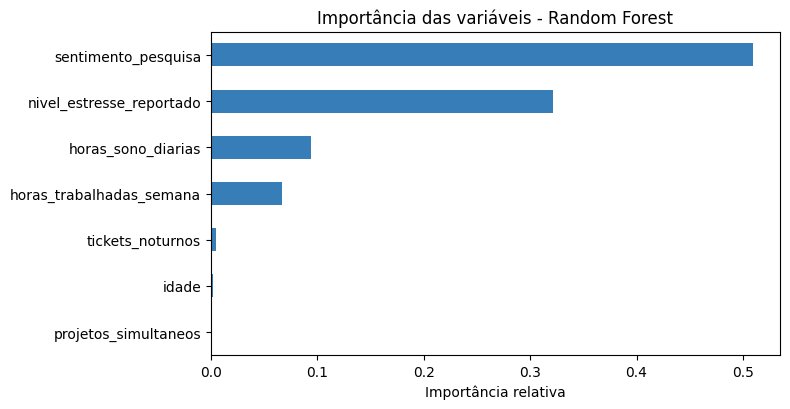

sentimento_pesquisa         50.9
nivel_estresse_reportado    32.1
horas_sono_diarias           9.4
horas_trabalhadas_semana     6.7
tickets_noturnos             0.5
idade                        0.2
projetos_simultaneos         0.1


In [20]:
# ==== Machine Learning (classificação): Regressão Logística x Random Forest ====
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.functions import vector_to_array

features = ["idade", "horas_trabalhadas_semana", "projetos_simultaneos", "horas_sono_diarias",
            "nivel_estresse_reportado", "tickets_noturnos", "sentimento_pesquisa"]

ml_df = wide.select("id_funcionario", "departamento", *features, F.col("risco_burnout").cast("double").alias("label"))

# SEPARAÇÃO POR FUNCIONÁRIO (não por linha): o mesmo colaborador aparece em 52 semanas; se as semanas dele ficassem
# nos dois conjuntos o modelo "reconheceria" a pessoa e a métrica ficaria inflada (vazamento de dados).
train = ml_df.filter(F.col("id_funcionario") % 10 < 7)     # ~70% dos funcionários
test  = ml_df.filter(F.col("id_funcionario") % 10 >= 7)    # ~30% dos funcionários (nunca vistos no treino)
n_tr, n_te = train.count(), test.count()
prev_tr = train.agg(F.avg("label")).first()[0]
prev_te = test.agg(F.avg("label")).first()[0]
print(f"Treino: {n_tr:,} registros | Teste: {n_te:,} registros")
print(f"Prevalência de risco alto -> treino: {prev_tr:.1%} | teste: {prev_te:.1%}  (classe desbalanceada)")

# Peso por classe: compensa o desbalanceamento sem descartar dados
peso_pos = (1 - prev_tr) / prev_tr
train = (train.withColumn("peso", F.when(F.col("label") == 1, F.lit(peso_pos)).otherwise(F.lit(1.0)))
              .withColumn("fold", F.col("id_funcionario") % 3))     # folds da validação cruzada também por funcionário

assembler = VectorAssembler(inputCols=features, outputCol="features")
auc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")

# --- Modelo 1: Regressão Logística (baseline linear, interpretável) ---
lr = LogisticRegression(featuresCol="features", labelCol="label", weightCol="peso", maxIter=100, standardization=True)
lr_model = Pipeline(stages=[assembler, lr]).fit(train)

# --- Modelo 2: Random Forest com validação cruzada (3 folds, por funcionário) ---
rf = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="peso", seed=42)
grade = ParamGridBuilder().addGrid(rf.numTrees, [40, 80]).addGrid(rf.maxDepth, [5, 8]).build()
cv = CrossValidator(estimator=Pipeline(stages=[assembler, rf]), estimatorParamMaps=grade, evaluator=auc,
                    numFolds=3, foldCol="fold", seed=42)
cv_model = cv.fit(train)
rf_model = cv_model.bestModel
melhor = rf_model.stages[-1]
print(f"\nMelhor Random Forest na validação cruzada: numTrees={melhor.getNumTrees}, maxDepth={melhor.getOrDefault('maxDepth')}")
print("AUC médio por combinação (validação cruzada):", [round(float(x), 3) for x in cv_model.avgMetrics])

# ---------- Avaliação no TESTE ----------
def metricas(pred, nome, limiar=0.5):
    p = pred.withColumn("p1", vector_to_array("probability")[1]).withColumn("yhat", (F.col("p1") >= limiar).cast("double"))
    r = p.agg(F.sum(F.when((F.col("label") == 1) & (F.col("yhat") == 1), 1).otherwise(0)).alias("tp"),
              F.sum(F.when((F.col("label") == 0) & (F.col("yhat") == 1), 1).otherwise(0)).alias("fp"),
              F.sum(F.when((F.col("label") == 1) & (F.col("yhat") == 0), 1).otherwise(0)).alias("fn"),
              F.sum(F.when((F.col("label") == 0) & (F.col("yhat") == 0), 1).otherwise(0)).alias("tn")).first()
    tp, fp, fn, tn = r["tp"], r["fp"], r["fn"], r["tn"]
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    return {"modelo": nome, "acuracia": (tp + tn) / (tp + tn + fp + fn), "precisao": prec, "recall": rec,
            "f1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0, "auc_roc": auc.evaluate(pred),
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}

pred_lr = lr_model.transform(test).cache()
pred_rf = rf_model.transform(test).cache()
m_lr, m_rf = metricas(pred_lr, "Regressão Logística"), metricas(pred_rf, "Random Forest")
base = {"modelo": "Baseline (sempre 'baixo')", "acuracia": 1 - prev_te, "precisao": 0.0, "recall": 0.0, "f1": 0.0, "auc_roc": 0.5,
        "tp": 0, "fp": 0, "fn": int(round(prev_te * n_te)), "tn": int(round((1 - prev_te) * n_te))}
tabela = pd.DataFrame([base, m_lr, m_rf]).set_index("modelo")
print("\n=== Desempenho no conjunto de TESTE (funcionários nunca vistos) ===")
print(tabela[["acuracia", "precisao", "recall", "f1", "auc_roc"]].round(3).to_string())

print("\n=== Matriz de confusão - Random Forest (limiar 0,5) ===")
print(pd.DataFrame([[m_rf["tn"], m_rf["fp"]], [m_rf["fn"], m_rf["tp"]]],
                   index=["Real: baixo", "Real: alto"], columns=["Previsto: baixo", "Previsto: alto"]).to_string())
tabela.to_csv("datalake/gold/metricas_modelos.csv")

# ---------- Importância das variáveis (Random Forest) ----------
imp = pd.Series(melhor.featureImportances.toArray(), index=features).sort_values()
plt.figure(figsize=(8, 4.2))
imp.plot(kind="barh", color="#377eb8")
plt.title("Importância das variáveis - Random Forest"); plt.xlabel("Importância relativa"); plt.tight_layout(); plt.show()
print((imp.sort_values(ascending=False) * 100).round(1).to_string())


**Interpretação dos resultados:**
- **Os dois modelos têm AUC ≈ 0,85** e o recall é de ~75%: o modelo encontra cerca de **3 em cada 4** semanas de risco alto em funcionários que nunca viu. É um resultado **bom, mas não perfeito**, o que é esperado, pois existe um fator individual não observável.
- A **acurácia (~78%) é menor que a do baseline (~84%)**, e isso é **intencional**: por usar pesos para priorizar a detecção, o modelo troca acertos fáceis da classe majoritária por recall. Esta é a razão de não avaliarmos por acurácia.
- **O preço é a precisão (~40%):** de cada 10 alertas, cerca de 6 são falsos positivos. A seção 11 mostra como escolher o limiar conforme o custo desse erro.
- **Regressão Logística e Random Forest empataram.** Isso não surpreende: os dados foram gerados por uma relação logística, o cenário em que o modelo linear é ideal. Em dados reais, com relações mais irregulares, o Random Forest teria mais chance de vencer, **hipótese que só dados reais podem confirmar**. Por ora, a logística é uma alternativa igualmente boa e mais simples de explicar.
- **Importância das variáveis:** sentimento e estresse somam a maior parte (~80%+), seguidos por sono e horas; `idade` e `projetos` quase não pesam, consistente com a EDA. **Cuidado:** como sentimento e estresse são quase redundantes (r = −0,83), a divisão da importância entre eles é arbitrária, e a conclusão correta é "o par estresse/sentimento é o sinal dominante", não "o sentimento vale 51%".

## 11. Do modelo à decisão

Um modelo só gera valor se virar uma regra de ação. O **limiar de alerta** define quantos alertas o RH recebe e quantos são reais. A tabela abaixo mostra o trade-off, e a segunda tabela mostra onde os alertas se concentram.

In [21]:
# ==== Do modelo à decisão: qual limiar de alerta usar? ====
print("Trade-off do limiar de alerta (Random Forest, conjunto de teste):")
linhas = []
for lim in [0.3, 0.4, 0.5, 0.6, 0.7]:
    m = metricas(pred_rf, "RF", limiar=lim)
    linhas.append({"limiar": lim, "alertas_emitidos": m["tp"] + m["fp"], "precisao": round(m["precisao"], 3),
                   "recall": round(m["recall"], 3), "f1": round(m["f1"], 3)})
print(pd.DataFrame(linhas).to_string(index=False))

print("\nRegistros-alvo de intervenção por departamento (limiar 0,5, conjunto de teste):")
(pred_rf.withColumn("p1", vector_to_array("probability")[1])
        .groupBy("departamento")
        .agg(F.count("*").alias("registros"),
             F.sum(F.when(F.col("p1") >= 0.5, 1).otherwise(0)).alias("alertas"),
             F.round(100 * F.avg(F.when(F.col("p1") >= 0.5, 1.0).otherwise(0.0)), 1).alias("pct_em_alerta"))
        .orderBy(F.desc("pct_em_alerta")).show())


Trade-off do limiar de alerta (Random Forest, conjunto de teste):
 limiar  alertas_emitidos  precisao  recall    f1
    0.3              3683     0.303   0.886 0.452
    0.4              2952     0.352   0.824 0.493
    0.5              2390     0.398   0.756 0.522
    0.6              1896     0.450   0.678 0.541
    0.7              1342     0.522   0.556 0.538

Registros-alvo de intervenção por departamento (limiar 0,5, conjunto de teste):
+------------+---------+-------+-------------+
|departamento|registros|alertas|pct_em_alerta|
+------------+---------+-------+-------------+
|   Operações|     2080|    817|         39.3|
|          TI|     2028|    655|         32.3|
|          RH|      780|    223|         28.6|
|      Vendas|     1716|    413|         24.1|
|   Marketing|     1196|    282|         23.6|
+------------+---------+-------+-------------+



**Recomendação de política de alerta (em dois níveis):**
- **Limiar alto (~0,7):** precisão ~52%, recall ~56%. Poucos alertas, mais confiáveis → **conversa individual prioritária** entre colaborador, gestor e RH.
- **Limiar baixo (~0,4):** recall ~82%, precisão ~35%. Muitos alertas, menos confiáveis → **monitoramento leve** (acompanhamento da carga, revisão de prioridades), sem ação individual.
- **Distribuição:** Operações e TI concentram a maior parte dos alertas (≈39% e ≈32% dos registros em alerta), reforçando o que a EDA e o OLAP já mostravam, e onde **ações estruturais** (redistribuição de carga, reforço de equipe nos fechamentos) rendem mais do que ações individuais.
- **Princípio:** o alerta é **apoio à conversa**, e não sentença. Deve haver sempre uma pessoa decidindo, nunca ação punitiva automática.

## 12. Análise final: insights, limitações e próximos passos
Painel consolidado, calculado diretamente a partir das tabelas do pipeline:

In [22]:
# ==== Painel de indicadores finais (calculado, não digitado) ====
taxa_geral = wide.agg(F.avg("risco_burnout")).first()[0]
por_dep = wide.groupBy("departamento").agg(F.avg("risco_burnout").alias("t")).orderBy(F.desc("t")).collect()
por_mes = wide.groupBy("mes").agg(F.avg("risco_burnout").alias("t")).orderBy(F.desc("t")).first()
fech = wide.filter(F.col("mes").isin(3, 6, 9, 12)).agg(F.avg("risco_burnout")).first()[0]
nao_fech = wide.filter(~F.col("mes").isin(3, 6, 9, 12)).agg(F.avg("risco_burnout")).first()[0]
crit = (wide.filter((F.col("horas_trabalhadas_semana") > 55) & (F.col("horas_sono_diarias") < 6))
            .agg(F.avg("risco_burnout")).first()[0])
top2 = imp.sort_values(ascending=False).head(2)
rf_ = tabela.loc["Random Forest"]

print("=" * 66)
print("PAINEL FINAL - RISCO DE BURNOUT")
print("=" * 66)
print(f"Registros analisados ............ {wide.count():,}  ({wide.select('id_funcionario').distinct().count()} colaboradores, 52 semanas)")
print(f"Taxa geral de risco alto ........ {taxa_geral:.1%}")
print(f"Setor de maior risco ............ {por_dep[0]['departamento']} ({por_dep[0]['t']:.1%}) | menor: {por_dep[-1]['departamento']} ({por_dep[-1]['t']:.1%})")
print(f"Mês de maior risco .............. {por_mes['mes']} ({por_mes['t']:.1%})")
print(f"Meses de fechamento vs demais ... {fech:.1%} vs {nao_fech:.1%}")
print(f"Risco com >55h E sono <6h ....... {crit:.1%}")
print(f"Random Forest (teste) ........... AUC {rf_['auc_roc']:.3f} | recall {rf_['recall']:.1%} | precisão {rf_['precisao']:.1%}")
print(f"Variáveis dominantes ............ {top2.index[0]} ({top2.iloc[0]:.0%}) e {top2.index[1]} ({top2.iloc[1]:.0%})")
print("=" * 66)

PAINEL FINAL - RISCO DE BURNOUT
Registros analisados ............ 26,000  (500 colaboradores, 52 semanas)
Taxa geral de risco alto ........ 18.1%
Setor de maior risco ............ Operações (22.2%) | menor: Marketing (13.6%)
Mês de maior risco .............. 6 (21.2%)
Meses de fechamento vs demais ... 21.0% vs 16.3%
Risco com >55h E sono <6h ....... 59.0%
Random Forest (teste) ........... AUC 0.849 | recall 75.6% | precisão 39.8%
Variáveis dominantes ............ sentimento_pesquisa (51%) e nivel_estresse_reportado (32%)


### 12.1 Insights para a tomada de decisão
1. **O risco é concentrado, e não uniforme:** Operações (~22%) e TI (~19–20%) estão acima da média; Marketing (~14%) está abaixo. As diferenças são estatisticamente significativas (qui-quadrado), mas **moderadas**: nenhum setor está livre de risco.
2. **O risco é sazonal:** os **meses de fechamento de trimestre** têm ~21% de risco contra ~16–17% nos demais. Antecipar reforço de equipe, congelar prazos extras e monitorar sono/horas nessas 3 semanas é a ação de maior retorno e **não depende de modelo**.
3. **Pressão de TI é estrutural** (tickets fora do expediente o ano todo), **a de Operações é carga horária**: exigem respostas diferentes (política de plantão e sobreaviso vs redimensionamento de equipe).
4. **Existem 4 perfis de risco**, e um deles (pressão noturna) **não aparece na autoavaliação**: só os dados operacionais o revelam. Pesquisas de clima isoladas deixam esse grupo invisível.
5. **Uma regra simples já funciona como primeiro alerta:** > 55 h/semana e < 6 h de sono → risco alto em ~44–67% dos casos, contra ~18% na base geral.
6. **O modelo antecipa ~3 em cada 4 casos** (AUC ≈ 0,85), mas com ~60% de falsos positivos no limiar padrão. Deve ser usado em **dois níveis de alerta**, com decisão humana.

### 12.2 Limitações
- **A base é sintética.** Os resultados mostram que o **pipeline funciona** e que o método é coerente, mas **não provam** que esses padrões existem em uma empresa real, nem que o modelo teria esse desempenho. A relação entre as variáveis foi definida por nós; o modelo a reaprende. Validar com dados reais (ou públicos de RH) é o passo mais importante.
- **Sentimento simulado:** o escore de NLP foi gerado a partir do estresse, então sua importância está superestimada. Com texto real, a qualidade do NLP em português seria uma fonte adicional de erro.
- **Autorrelato:** sono e estresse dependem de pesquisa respondida pelo próprio funcionário (viés de autopercepção e receio de exposição).
- **Rótulo único e semanal:** "burnout" real é um quadro clínico que se desenvolve ao longo de meses; o rótulo semanal aqui é uma aproximação de **risco**, não de diagnóstico.
- **Correlação, não causa:** associações (setor × risco, horas × estresse) não provam causalidade.
- **Sem série temporal no modelo:** cada semana é prevista de forma independente; um modelo que use o histórico recente de cada pessoa tenderia a ser melhor.
- **Ética e LGPD:** dados de saúde mental e monitoramento individual são sensíveis. Em produção exigem base legal, finalidade clara, minimização, anonimização/agregação sempre que possível, transparência com os colaboradores e proibição de uso punitivo.

### 12.3 Próximos passos
1. Substituir/complementar a base por **dados reais ou públicos** de RH e comparar o desempenho.
2. Aplicar **NLP real** (análise de sentimento em português) aos comentários da pesquisa.
3. Incluir **variáveis temporais** (médias móveis das últimas 4 semanas) e testar modelos sequenciais.
4. **Orquestrar** a ingestão e o processamento em contêineres Docker agendados.
5. Construir um **painel** (dashboard) para o RH, com alertas em dois níveis e visão por setor.
6. Definir com o RH/jurídico a **política de uso** dos alertas (quem vê o quê, e para qual finalidade).

In [23]:
# ==== (Opcional) Exportar os artefatos do Data Lake para o seu computador ====
import shutil
shutil.make_archive("entrega_burnout", "zip", "datalake")
shutil.copy("arquitetura.png", "datalake/")
shutil.copy("esquema_estrela.png", "datalake/")
print("✅ Arquivo 'entrega_burnout.zip' criado (raw, silver, gold, dicionário e métricas).")
try:
    from google.colab import files
    files.download("entrega_burnout.zip")
    files.download("arquitetura.png")
    files.download("esquema_estrela.png")
except Exception:
    print("(Fora do Colab: baixe os arquivos manualmente na pasta atual.)")

✅ Arquivo 'entrega_burnout.zip' criado (raw, silver, gold, dicionário e métricas).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>